# 0. SETUP & DATA LOADING

In [90]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns
import os
import gc

# Visual style
plt.rcParams.update({
    'figure.figsize': (14, 6),
    'figure.dpi': 100,
    'axes.titleweight': 'bold',
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.facecolor': '#fafafa',
    'axes.facecolor': '#fafafa',
})
sns.set_theme(style='whitegrid')

In [91]:
# Dynamic path configuration (Kaggle / Local)
KAGGLE_PATH = '/kaggle/input/datasets/pgnjams/narrativecastdataset-ie403/reddit_technology_madoc-001.parquet'
LOCAL_FULL  = '../data/raw/reddit_technology_madoc-001.parquet'
LOCAL_SAMPLE = '../data/sample/madoc_sample.parquet'

if os.path.exists('/kaggle/input'):
    DATA_PATH  = KAGGLE_PATH
    OUTPUT_DIR = '/kaggle/working/temporal_eda/'
    print("Running on Kaggle — full dataset.")
elif os.path.exists(LOCAL_FULL):
    DATA_PATH  = LOCAL_FULL
    OUTPUT_DIR = '../outputs/temporal_eda/'
    print("Running on Local — full dataset.")
else:
    DATA_PATH  = LOCAL_SAMPLE
    OUTPUT_DIR = '../outputs/temporal_eda/'
    print("Running on Local — SAMPLE fallback.")

os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Data : {DATA_PATH}")
print(f"Output: {OUTPUT_DIR}")

Running on Local — full dataset.
Data : ../data/raw/reddit_technology_madoc-001.parquet
Output: ../outputs/temporal_eda/


In [92]:
# Load 6 cột cần dùng (không load content, url, strict_filter,language)
LOAD_COLS = [
    'post_id', 'publish_date', 'user_id',
    'parent_id', 'interaction_type', 'sentiment_vader'
]

try:
    if DATA_PATH.endswith('.parquet'):
        df = pd.read_parquet(DATA_PATH, columns=LOAD_COLS)
    else:
        df = pd.read_csv(DATA_PATH, usecols=LOAD_COLS)
    print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
except Exception as e:
    print(f"Error: {e}")
    raise

# Memory footprint optimization & temporal schema parsing
# Convert UNIX timestamp to UTC datetime for temporal windowing
# Downcast interaction_type to category and sentiment_vader to float32
df['publish_date'] = pd.to_datetime(df['publish_date'], unit='s', utc=True)
df['interaction_type'] = df['interaction_type'].astype('category')
df['sentiment_vader'] = df['sentiment_vader'].astype('float32')

mem_mb = df.memory_usage(deep=True).sum() / (1024**2)
print(f"\nMemory: {mem_mb:,.1f} MB")
print(f"Timeline: {df['publish_date'].min()} ->{df['publish_date'].max()}")
print(f"\nDtypes:\n{df.dtypes}")
gc.collect()

Loaded: 11,766,134 rows × 6 columns

Memory: 2,443.4 MB
Timeline: 2014-01-01 00:00:16+00:00 ->2020-12-31 23:59:25+00:00

Dtypes:
post_id                          object
publish_date        datetime64[ns, UTC]
user_id                          object
parent_id                        object
interaction_type               category
sentiment_vader                 float32
dtype: object


0

In [93]:
# Pre-compute bảng tổng hợp theo ngày
print("Computing daily aggregate ")

daily_agg = df.groupby(df['publish_date'].dt.floor('D')).agg(
    volume=('post_id', 'size'),
    unique_users=('user_id', 'nunique'),
    mean_sentiment=('sentiment_vader', 'mean'),
    std_sentiment=('sentiment_vader', 'std'),
)

# Thêm số lượng POST / COMMENT theo ngày
_tc = df.groupby(
    [df['publish_date'].dt.floor('D'), 'interaction_type'], observed=False
).size().unstack(fill_value=0)

for col_new, col_orig in [('post_count', 'POST'), ('comment_count', 'COMMENT')]:
    daily_agg[col_new] = _tc[col_orig].values if col_orig in _tc.columns else 0

daily_agg['amplification'] = (
    daily_agg['comment_count'] / daily_agg['post_count'].replace(0, np.nan)
)
daily_agg['posts_per_user'] = daily_agg['volume'] / daily_agg['unique_users']

# Bỏ timezone
daily_agg.index = daily_agg.index.tz_localize(None)
daily_agg.index.name = 'date'

del _tc
gc.collect()

print(f"daily_agg: {daily_agg.shape[0]:,} ngay x {daily_agg.shape[1]} cot")
print(f"Memory: {daily_agg.memory_usage(deep=True).sum() / 1024:.1f} KB\n")
daily_agg.describe().round(2)

Computing daily aggregate 
daily_agg: 2,557 ngay x 8 cot
Memory: 159.8 KB



,volume,unique_users,mean_sentiment,std_sentiment,post_count,comment_count,amplification,posts_per_user
count,2557.00,2557.00,2557.00,2557.00,2557.00,2557.00,2546.00,2557.00
mean,4601.54,2732.69,0.05,0.48,331.50,4270.03,14.61,1.68
std,1630.89,911.85,0.03,0.02,139.74,1572.71,7.16,0.11
min,1372.00,895.00,-0.14,0.42,0.00,1199.00,4.04,1.37
25%,3456.00,2089.00,0.03,0.47,216.00,3160.00,9.63,1.60
50%,4331.00,2587.00,0.06,0.48,333.00,3991.00,12.88,1.67
75%,5428.00,3220.00,0.08,0.50,431.00,5054.00,17.62,1.74
max,17054.00,8794.00,0.18,0.55,883.00,16538.00,65.59,2.70


**Nhận xét — Setup & Tối ưu RAM:**

- Chỉ load **6/13 cột** (`post_id`, `publish_date`, `user_id`, `parent_id`, `interaction_type`, `sentiment_vader`), bỏ qua `content`, `url`, `strict_filter`, `parent_user_id`, `language`, `platform`, `community`.
- Ép kiểu : `interaction_type -> category` , `sentiment_vader -> float32`.
- Bảng `daily_agg` (~2,557 dòng) được tính **một lần** và tái sử dụng xuyên suốt notebook, tránh groupby lặp trên 11.76M dòng.

# 1. KIỂM ĐỊNH TÍNH LIÊN TỤC CHUỖI THỜI GIAN & ĐỘ LỆCH THỨ TỰ
Kiểm tra xem dữ liệu gốc có bị xáo trộn thứ tự timestamp không, và có ngày nào trong khoảng 2014–2020 bị 0 bài đăng hay không. 
Kết luận ảnh hưởng trực tiếp đến thiết kế cửa sổ trượt $W_{hist}=7$ ngày.

In [94]:
# 1.1 — Out-of-order check
is_sorted = df['publish_date'].is_monotonic_increasing
out_of_order = int((df['publish_date'].diff() < pd.Timedelta(0)).sum())

print("=== KIỂM TRA THỨ TỰ THỜI GIAN ===")
print(f"Dữ liệu đã sắp xếp tăng dần? {'CÓ' if is_sorted else 'KHÔNG'}")
print(f"Số dòng vi phạm thứ tự: {out_of_order:,} ({out_of_order/len(df)*100:.2f}%)")

if not is_sorted:
    print("\n Khuyến nghị: BẮT BUỘC sort theo publish_date trước khi chia cửa sổ thời gian.")

=== KIỂM TRA THỨ TỰ THỜI GIAN ===
Dữ liệu đã sắp xếp tăng dần? CÓ
Số dòng vi phạm thứ tự: 0 (0.00%)


**Nhận xét — Thứ tự thời gian (Kết quả thực tế):**

- Dữ liệu được sắp tăng dần trong file data gốc — có **0 dòng vi phạm thứ tự**,`is_monotonic_increasing` trả về `True`, cho thấy dữ liệu MADOC đã được sắp xếp sẵn theo `publish_date`.
- **Đề xuất cho `clean_data.py`:** Dù dữ liệu hiện tại đã sorted, bước tiền xử lý vẫn nên **luôn sort theo `publish_date`** để đảm bảo an toàn khi chia cửa sổ trượt.

In [95]:
# 1.2 — Gap detection: có ngày nào thiếu hoàn toàn (0 bài đăng)?
full_range = pd.date_range(
    start=daily_agg.index.min(),
    end=daily_agg.index.max(),
    freq='D'
)
missing_dates = full_range.difference(daily_agg.index)

total_days = len(full_range)
data_days = len(daily_agg)

print("=== KIỂM TRA KHOẢNG TRỐNG THỜI GIAN ===")
print(f"Khoảng thời gian: {full_range[0].date()} -> {full_range[-1].date()}")
print(f"Tổng ngày trong khoảng: {total_days:,}")
print(f"Ngày có dữ liệu:       {data_days:,}")
print(f"Ngày bị thiếu (gaps):   {len(missing_dates)}")

if len(missing_dates) > 0:
    print(f"\nDanh sách ngày thiếu:")
    for d in missing_dates[:20]:
        print(f"  - {d.date()}")
    if len(missing_dates) > 20:
        print(f"  ... và {len(missing_dates) - 20} ngày khác")
else:
    print("\n Chuỗi thời gian LIÊN TỤC — không có ngày nào bị mất.")

# Chuỗi liên tục dài nhất
streak_lengths = daily_agg.index.to_series().diff().dt.days
max_gap = streak_lengths.max()
print(f"\nKhoảng cách lớn nhất giữa 2 ngày liên tiếp: {max_gap} ngày")

=== KIỂM TRA KHOẢNG TRỐNG THỜI GIAN ===
Khoảng thời gian: 2014-01-01 -> 2020-12-31
Tổng ngày trong khoảng: 2,557
Ngày có dữ liệu:       2,557
Ngày bị thiếu (gaps):   0

 Chuỗi thời gian LIÊN TỤC — không có ngày nào bị mất.

Khoảng cách lớn nhất giữa 2 ngày liên tiếp: 1.0 ngày


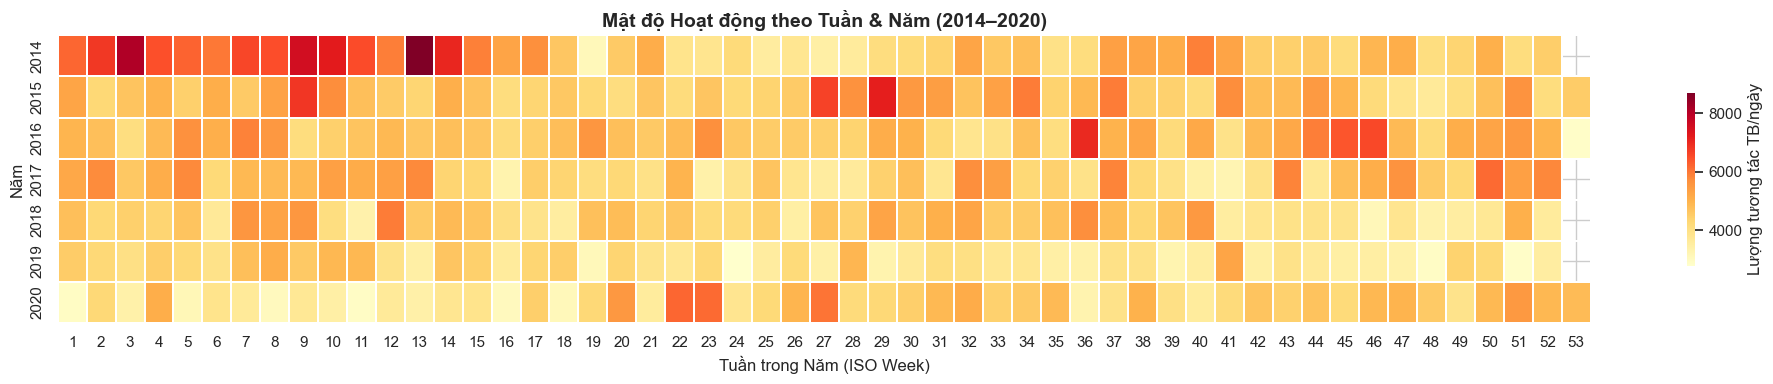

33

In [96]:
# 1.3 — Heatmap mật độ hoạt động: Năm × Tuần
daily_vol_full = daily_agg['volume'].reindex(full_range, fill_value=0)

hm_df = pd.DataFrame({
    'year': daily_vol_full.index.year,
    'week': daily_vol_full.index.isocalendar().week.astype(int),
    'volume': daily_vol_full.values,
})
hm_pivot = hm_df.pivot_table(
    index='year', columns='week', values='volume', aggfunc='mean'
)

fig, ax = plt.subplots(figsize=(20, 4))
sns.heatmap(
    hm_pivot, cmap='YlOrRd', ax=ax, linewidths=0.1, linecolor='white',
    cbar_kws={'label': 'Lượng tương tác TB/ngày', 'shrink': 0.6},
)
ax.set_title('Mật độ Hoạt động theo Tuần & Năm (2014–2020)', fontsize=14)
ax.set_xlabel('Tuần trong Năm (ISO Week)')
ax.set_ylabel('Năm')

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, '01_temporal_continuity_heatmap.pdf'),
    format='pdf', bbox_inches='tight'
)
plt.show()

del daily_vol_full, hm_df, hm_pivot
gc.collect()

**Nhận xét — Tính liên tục chuỗi thời gian (Kết quả thực tế):**

- Dataset bao trùm **2,557 ngày** liên tục (01/01/2014 -> 31/12/2020), không có ngày nào thiếu dữ liệu (**0 gaps**).
- Khoảng cách lớn nhất giữa 2 ngày liên tiếp = **1.0 ngày** -> chuỗi thời gian liên tục 100%.
- Daily volume min = **1,372 bài/ngày** -> mỗi ngày đều có đủ dữ liệu để tính features.
- **Đề xuất thiết kế sliding window:** Mỗi cửa sổ lịch sử $W_{hist}=7$ ngày luôn có đủ 7 ngày dữ liệu, **không cần padding** hay bỏ qua window thiếu dữ liệu. Tổng số cửa sổ khả dụng = 2,557 - 7 + 1 = **2,551 windows**.

# 2. CHU KỲ MÙA VỤ NỘI TUẦN & TRONG NGÀY (Seasonality)
Chứng minh sự biến thiên lưu lượng giữa ngày trong tuần và cuối tuần làm căn cứ cho việc chọn $W_{hist}=7$ ngày. Đồng thời phân tích phân bố trong ngày (24h) và kiểm tra tính ổn định qua 7 năm.

In [97]:
# 2.1 — Day-of-Week & Hour-of-Day volume
dow_counts = df.groupby(df['publish_date'].dt.dayofweek).size()
dow_pct = (dow_counts / dow_counts.sum() * 100).round(2)
DOW_NAMES = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow_counts.index = DOW_NAMES

hour_counts = df.groupby(df['publish_date'].dt.hour).size()

# Tính tỷ lệ weekday vs weekend
weekday_mean = dow_counts.iloc[:5].mean()
weekend_mean = dow_counts.iloc[5:].mean()
weekend_ratio = weekend_mean / weekday_mean

print("=== PHÂN BỐ THEO NGÀY TRONG TUẦN ===")
for day, cnt, pct in zip(DOW_NAMES, dow_counts.values, dow_pct.values):
    marker = 'Weekend' if day in ('Sat', 'Sun') else ''
    print(f"  {day}: {cnt:>10,} ({pct:5.2f}%){marker}")
print(f"\n  Weekday TB:  {weekday_mean:,.0f}")
print(f"  Weekend TB:  {weekend_mean:,.0f}")
print(f"  Weekend/Weekday ratio: {weekend_ratio:.3f}")

print(f"\n=== GIỜ TRONG NGÀY (Top 5 cao nhất) ===")
top_hours = hour_counts.nlargest(5)
for h, cnt in top_hours.items():
    print(f"  {h:02d}:00 UTC -> {cnt:>10,}")

=== PHÂN BỐ THEO NGÀY TRONG TUẦN ===
  Mon:  1,683,018 (14.30%)
  Tue:  1,863,224 (15.84%)
  Wed:  1,875,645 (15.94%)
  Thu:  1,838,618 (15.63%)
  Fri:  1,756,785 (14.93%)
  Sat:  1,417,138 (12.04%)Weekend
  Sun:  1,331,706 (11.32%)Weekend

  Weekday TB:  1,803,458
  Weekend TB:  1,374,422
  Weekend/Weekday ratio: 0.762

=== GIỜ TRONG NGÀY (Top 5 cao nhất) ===
  16:00 UTC ->    776,186
  17:00 UTC ->    760,115
  15:00 UTC ->    739,347
  18:00 UTC ->    715,194
  19:00 UTC ->    668,299


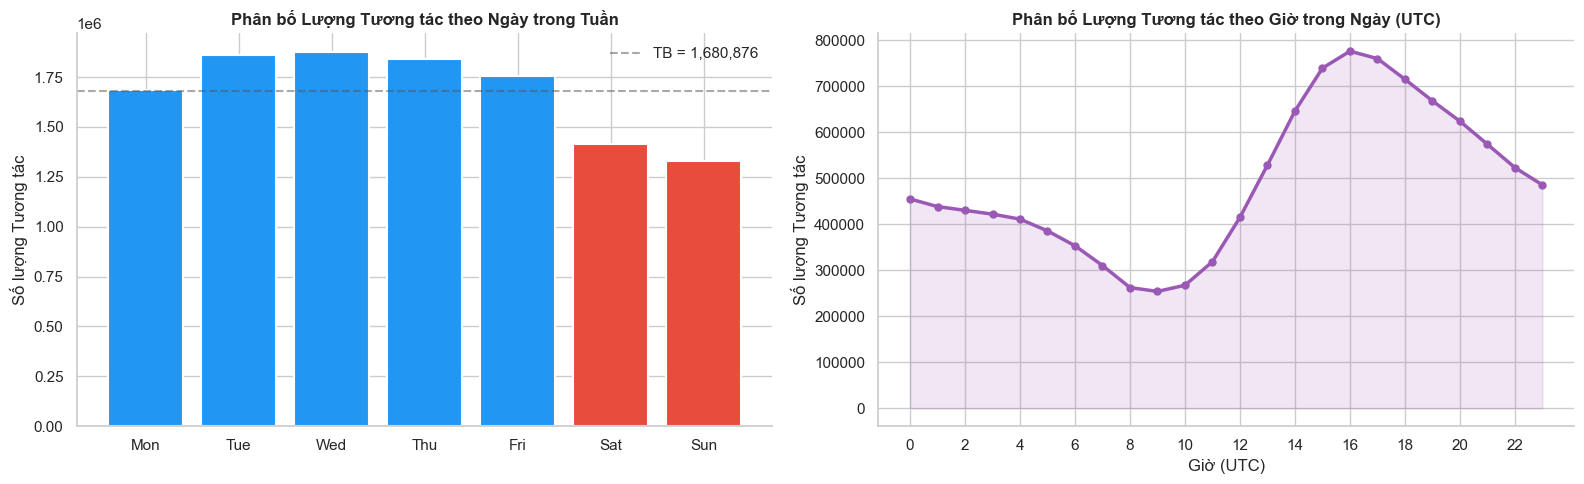

In [98]:
# 2.2 — Biểu đồ kép: Bar DOW + Line Hour
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Bar chart Day-of-Week
colors_dow = ['#2196F3'] * 5 + ['#e74c3c'] * 2  # Weekday blue, Weekend red
ax1.bar(DOW_NAMES, dow_counts.values, color=colors_dow, edgecolor='white', linewidth=1.5)
ax1.set_title('Phân bố Lượng Tương tác theo Ngày trong Tuần')
ax1.set_ylabel('Số lượng Tương tác')
ax1.axhline(dow_counts.mean(), color='#555', ls='--', alpha=0.5, label=f'TB = {dow_counts.mean():,.0f}')
ax1.legend(frameon=False)

# Line chart Hour-of-Day
ax2.plot(hour_counts.index, hour_counts.values, color='#9b59b6', linewidth=2.5, marker='o', markersize=5)
ax2.fill_between(hour_counts.index, hour_counts.values, alpha=0.15, color='#9b59b6')
ax2.set_title('Phân bố Lượng Tương tác theo Giờ trong Ngày (UTC)')
ax2.set_xlabel('Giờ (UTC)')
ax2.set_ylabel('Số lượng Tương tác')
ax2.set_xticks(range(0, 24, 2))

for ax in (ax1, ax2):
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '02_weekly_hourly_seasonality.pdf'), format='pdf', bbox_inches='tight')
plt.show()

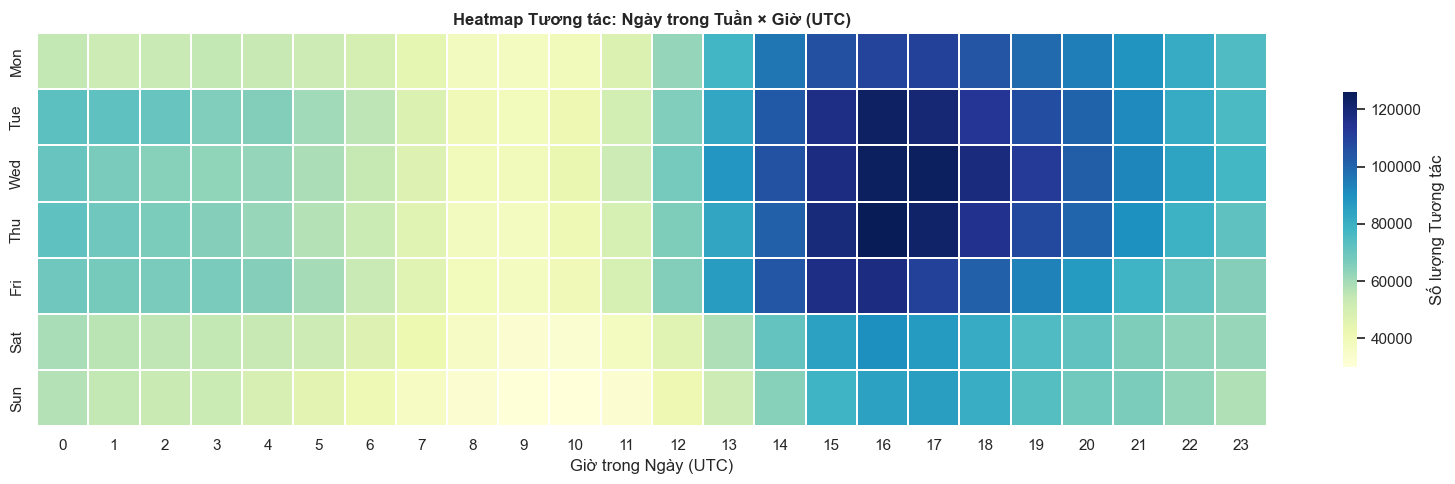

16374

In [99]:
# 2.3 — Heatmap DOW × Hour
dow_hour = df.groupby(
    [df['publish_date'].dt.dayofweek, df['publish_date'].dt.hour]
).size().unstack(fill_value=0)
dow_hour.index = DOW_NAMES

fig, ax = plt.subplots(figsize=(16, 5))
sns.heatmap(
    dow_hour, cmap='YlGnBu', annot=False, fmt=',', ax=ax,
    cbar_kws={'label': 'Số lượng Tương tác', 'shrink': 0.7},
    linewidths=0.3, linecolor='white',
)
ax.set_title('Heatmap Tương tác: Ngày trong Tuần × Giờ (UTC)')
ax.set_xlabel('Giờ trong Ngày (UTC)')
ax.set_ylabel('')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '03_dow_hour_heatmap.pdf'), format='pdf', bbox_inches='tight')
plt.show()

del dow_hour
gc.collect()

=== BẢNG PHÂN BỐ % TƯƠNG TÁC THEO THỨ TRONG TUẦN QUA TỪNG NĂM ===
publish_date   2014   2015   2016   2017   2018   2019   2020
Mon           14.79  14.35  14.10  14.66  14.93  13.61  13.51
Tue           15.60  15.48  15.28  16.79  15.50  16.83  15.56
Wed           16.48  16.71  15.64  15.32  15.07  16.10  16.20
Thu           16.37  15.64  15.89  15.98  14.51  15.62  15.20
Fri           15.09  15.03  16.02  14.54  14.34  15.22  14.14
Sat           10.72  11.49  12.04  11.66  13.20  11.76  13.76
Sun           10.96  11.31  11.03  11.04  12.45  10.86  11.64


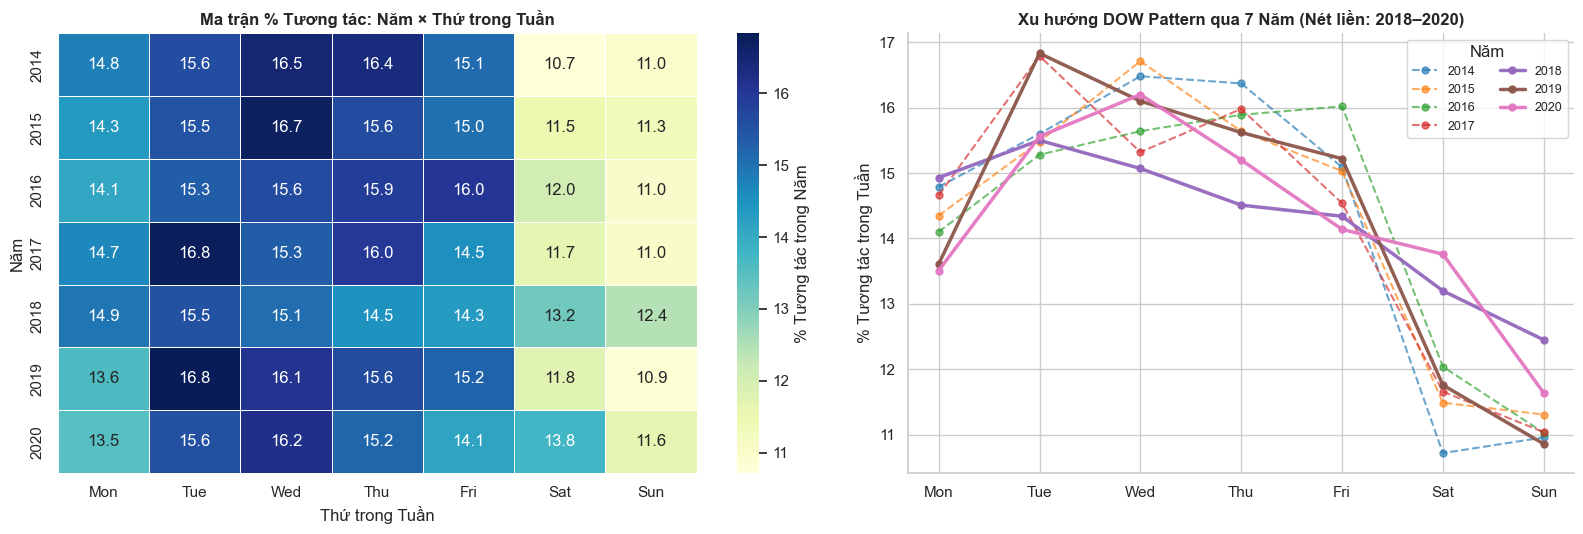

7263

In [100]:
# 2.4 — Kiểm tra tính ổn định DOW pattern qua 7 năm (Kèm bảng số liệu & Biểu đồ rõ nét)
dow_by_year = df.groupby(
    [df['publish_date'].dt.year, df['publish_date'].dt.dayofweek]
).size().unstack(level=0)
dow_by_year.index = DOW_NAMES

# Chuẩn hóa thành % cho mỗi năm
dow_by_year_pct = (dow_by_year.div(dow_by_year.sum(axis=0), axis=1) * 100).round(2)

print("=== BẢNG PHÂN BỐ % TƯƠNG TÁC THEO THỨ TRONG TUẦN QUA TỪNG NĂM ===")
print(dow_by_year_pct.to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1.2, 1]})

# Trái: Heatmap trực quan có số % cụ thể
sns.heatmap(
    dow_by_year_pct.T, cmap='YlGnBu', annot=True, fmt='.1f',
    linewidths=0.5, linecolor='white', ax=ax1,
    cbar_kws={'label': '% Tương tác trong Năm'}
)
ax1.set_title('Ma trận % Tương tác: Năm × Thứ trong Tuần')
ax1.set_ylabel('Năm')
ax1.set_xlabel('Thứ trong Tuần')

# Phải: Line chart dùng bảng màu tương phản cao (tab10) + nét đứt cho các năm đầu
palette = sns.color_palette('tab10', len(dow_by_year_pct.columns))
for i, year in enumerate(dow_by_year_pct.columns):
    ls = '--' if year < 2018 else '-'
    lw = 1.5 if year < 2018 else 2.5
    alpha = 0.65 if year < 2018 else 0.95
    ax2.plot(
        DOW_NAMES, dow_by_year_pct[year],
        marker='o', markersize=5, linewidth=lw, linestyle=ls,
        color=palette[i], label=str(year), alpha=alpha
    )

ax2.set_title('Xu hướng DOW Pattern qua 7 Năm (Nét liền: 2018–2020)')
ax2.set_ylabel('% Tương tác trong Tuần')
ax2.legend(title='Năm', frameon=True, fontsize=9, ncol=2)
sns.despine(ax=ax2)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '04_dow_stability_by_year.pdf'), format='pdf', bbox_inches='tight')
plt.show()

del dow_by_year, dow_by_year_pct
gc.collect()

**Nhận xét — Chu kỳ Mùa vụ (Kết quả thực tế):**

- **Day-of-Week (Biểu đồ 02 trái & 03):** Tỷ lệ `weekend/weekday = 0.762` - Trung bình ngày thường đạt **~1.80M** tương tác so với cuối tuần đạt **~1.37M** tương tác (lưu lượng cuối tuần giảm **~23.8%** so với ngày trong tuần). Điều này xác nhận quy luật chu kỳ 7 ngày rõ rệt trên `r/technology`.
- **Biện minh chọn $W_{hist}=7$ ngày:** Cửa sổ quan sát lịch sử 7 ngày bao trùm trọn vẹn 1 chu kỳ tuần (5 ngày làm việc + 2 ngày cuối tuần), giúp triệt tiêu độ lệch mùa vụ nội tuần (day-of-week bias).
- **Đánh giá đường chân trời dự báo $h \in \{3, 7, 14\}$ ngày:** Với $h=7$ và $h=14$ ngày (bội số của 7), mục tiêu dự báo $y_{n,t,h}$ miễn nhiễm với hiệu ứng ngày cuối tuần. Riêng với $h=3$ ngày, cửa sổ tương lai ngắn hơn 1 chu kỳ tuần nên tổng lượng bài $N_t$ sẽ dao động tùy thuộc mốc dự đoán $t$ rơi vào đầu tuần hay cuối tuần - việc chuẩn hóa bằng tỷ trọng **Prominence $P(n, W_t) = N_{n,t}/N_t$** giúp giảm thiểu ảnh hưởng của sự dao động khối lượng tuyệt đối này.
- **Hour-of-Day (Biểu đồ 02 phải & 03):** Đỉnh tương tác tập trung từ **15:00–19:00 UTC** (tương ứng giờ làm việc buổi sáng - đầu giờ chiều tại Bắc Mỹ), thấp nhất vào **08:00–10:00 UTC**.
- **Tính ổn định & Dịch chuyển hành vi qua 7 năm (Biểu đồ 04):** Cấu trúc "cao trong tuần, thấp cuối tuần" duy trì xuyên suốt 2014–2020. Tuy nhiên có sự dịch chuyển đáng chú ý: giai đoạn 2014–2016 đạt đỉnh vào Thứ Tư - Thứ Năm (~16.0%–16.7%), giai đoạn 2018–2019 đỉnh dồn sang Thứ Ba (~16.8%), và riêng năm **2020** (ảnh hưởng của đại dịch COVID-19 / làm việc tại nhà) đường phân phối phẳng hơn khi tỷ lệ tương tác Thứ Bảy tăng lên ~13.8% (so với ~10.7% năm 2014).

# 3. ĐỘNG LỰC POST vs. COMMENT & TỶ LỆ KHUẾCH ĐẠI THẢO LUẬN
Phân tích tỷ lệ khuếch đại thảo luận $\text{Amplification} = \frac{\text{COMMENT}}{\text{POST}}$ theo thời gian

=== TỶ LỆ KHUẾCH ĐẠI THẢO LUẬN ===
Tổng thể: 12.88 COMMENT / POST

Amplification theo tuần:
count    366.00
mean      13.97
std        8.18
min        6.84
25%       11.13
50%       12.73
75%       15.30
max      146.21
Name: amplification, dtype: float64


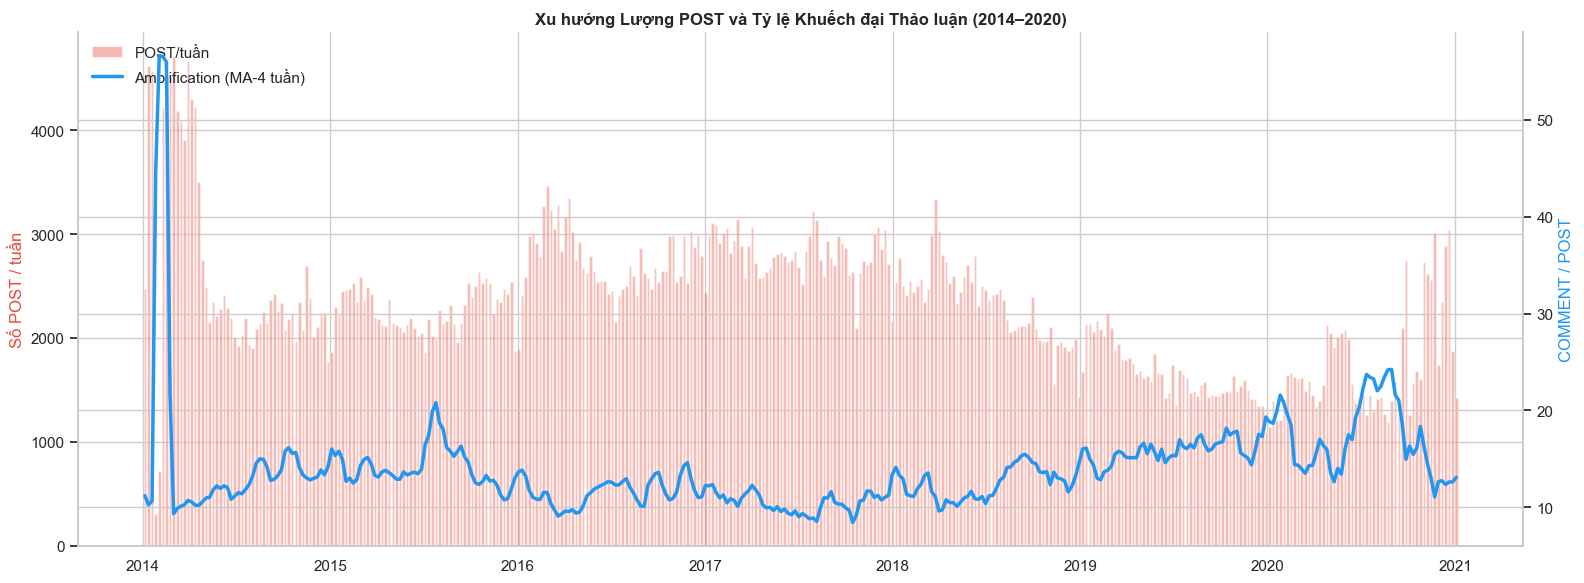

In [101]:
# 3.1 — Xu hướng Amplification Ratio theo thời gian
weekly_agg = daily_agg.resample('W').agg({
    'post_count': 'sum',
    'comment_count': 'sum',
    'volume': 'sum',
})
weekly_agg['amplification'] = (
    weekly_agg['comment_count'] / weekly_agg['post_count'].replace(0, np.nan)
)

# Rolling 4-week smoothing
rolling_amp = weekly_agg['amplification'].rolling(4, min_periods=1).mean()

# Thống kê
overall_amp = daily_agg['comment_count'].sum() / daily_agg['post_count'].sum()
print("=== TỶ LỆ KHUẾCH ĐẠI THẢO LUẬN ===")
print(f"Tổng thể: {overall_amp:.2f} COMMENT / POST")
print(f"\nAmplification theo tuần:")
print(weekly_agg['amplification'].describe().round(2))

# Biểu đồ dual-axis
fig, ax1 = plt.subplots(figsize=(16, 6))
ax2 = ax1.twinx()

ax1.bar(weekly_agg.index, weekly_agg['post_count'], width=5, alpha=0.4,
        color='#e74c3c', label='POST/tuần')
ax2.plot(weekly_agg.index, rolling_amp, color='#2196F3', linewidth=2.5,
         label='Amplification (MA-4 tuần)')

ax1.set_ylabel('Số POST / tuần', color='#e74c3c')
ax2.set_ylabel('COMMENT / POST', color='#2196F3')
ax1.set_title('Xu hướng Lượng POST và Tỷ lệ Khuếch đại Thảo luận (2014–2020)')
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=False)
sns.despine(right=False)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '05_amplification_ratio_trend.pdf'), format='pdf', bbox_inches='tight')
plt.show()

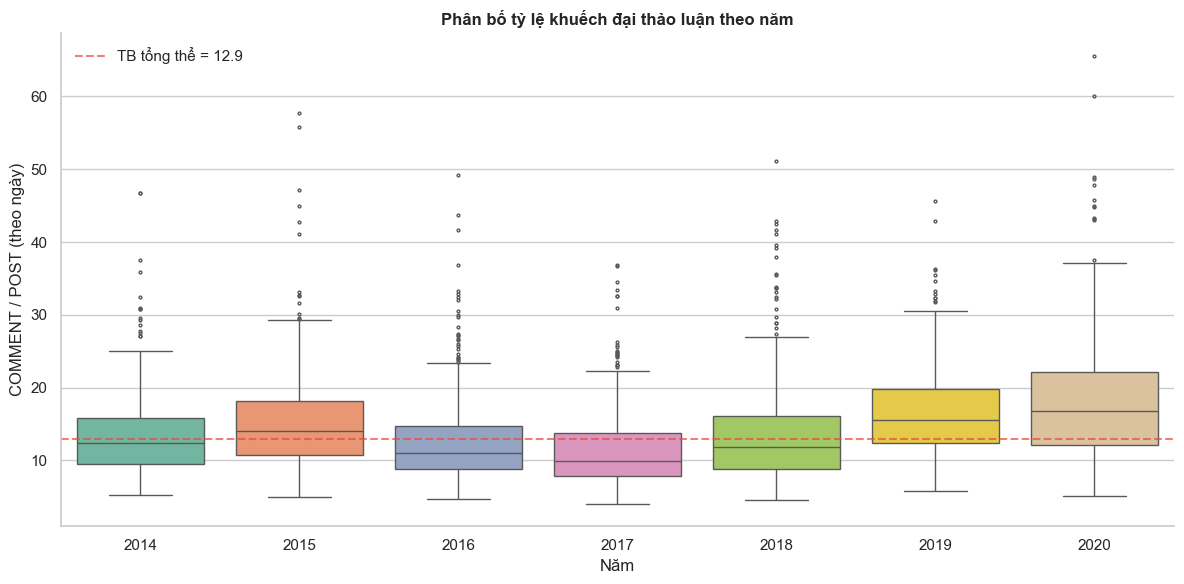

24855

In [102]:
# 3.2 — Boxplot Amplification Ratio theo nam
daily_agg_plot = daily_agg.copy()
daily_agg_plot['year'] = daily_agg_plot.index.year

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=daily_agg_plot, x='year', y='amplification',
    hue='year', legend=False,
    palette='Set2', fliersize=2, ax=ax,
)
ax.set_title('Phân bố tỷ lệ khuếch đại thảo luận theo năm')
ax.set_xlabel('Năm')
ax.set_ylabel('COMMENT / POST (theo ngày)')
ax.axhline(overall_amp, color='#e74c3c', ls='--', alpha=0.7, label=f'TB tổng thể = {overall_amp:.1f}')
ax.legend(frameon=False)
sns.despine()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '06_amplification_by_year_boxplot.pdf'), format='pdf', bbox_inches='tight')
plt.show()

del daily_agg_plot, weekly_agg, rolling_amp
gc.collect()

**Nhận xét — Tỷ lệ Khuếch đại Thảo luận (Kết quả thực tế):**

- **Tổng thể:** Trung bình mỗi bài `POST` thu hút **12.88 `COMMENT`** (trung vị theo tuần = **12.73**, trung bình tuần = **13.97**), phản ánh mức độ thảo luận chuyên sâu cao của cộng đồng `r/technology`.
- **Phát hiện bất thường dữ liệu đầu năm 2014 (Biểu đồ 05):** Có **11 ngày** (rơi vào khoảng tháng 2–tháng 3/2014) ghi nhận `post_count = 0` nhưng vẫn có hàng ngàn `COMMENT`, khiến tỷ lệ khuếch đại tuần tại thời điểm đó vọt lên cực đại **146.21** (tạo thành cột gai nhọn > 50 vào quý 1/2014 trên đường `MA-4 tuần`). Đây là hiện tượng khuyết cục bộ bản ghi `POST` trong dữ liệu nguồn Pushshift ở một số ngày đầu năm 2014 (Data Collection Artifact).
- **Sự dịch chuyển cấu trúc thảo luận giai đoạn 2018–2020 (Biểu đồ 05 & Boxplot 06):**
  - *Về số lượng bài mở đầu (`POST/tuần` trên Biểu đồ 05):* Duy trì ở mức cao trong giai đoạn 2016–2017 (~2,500–3,200 POST/tuần), giảm dần từ năm 2018 (~1,800–2,500 bài) xuống vùng ~1,200–2,000 POST/tuần vào giữa năm 2019 – nửa đầu 2020, trước khi phục hồi lên ~2,500–3,000 bài vào cuối năm 2020.
  - *Về độ sâu thảo luận (`COMMENT/POST` trên Biểu đồ Boxplot 06):* Trung vị giảm xuống đáy vào năm **2017 (~10.0)**, nhưng **tăng mạnh và liên tục** từ năm **2018 (~12.0)** lên **2019 (~15.5)** và đạt đỉnh vào năm **2020 (~17.0, phân vị 75% vượt trên 22 COMMENT/POST)**.
  - **Ý nghĩa cho đề tài:** Giai đoạn **2018–2020**, cộng đồng chuyển dịch từ đăng bài dàn trải sang tập trung thảo luận/tranh luận sâu sắc hơn gấp rưỡi trên mỗi chủ đề. Khi thiết kế đặc trưng (Feature Engineering), cần tách riêng `post_volume`, `comment_volume` và `amplification_ratio`, đồng thời xử lý 11 ngày khuyết `POST` đầu năm 2014 trong `clean_data.py`.

# 4. SỰ ĐỨT GÃY LIÊN KẾT HỘI THOẠI (`parent_id` Missingness Over Time)
Kiểm tra tỷ lệ thiếu `parent_id` ở bản ghi COMMENT phân bố đều qua 7 năm hay tập trung ở một giai đoạn cụ thể. Ảnh hưởng trực tiếp đến Section 6 (Reply Lag).

=== PARENT_ID MISSINGNESS (chỉ COMMENT) ===
Tổng COMMENT:                10,918,477
COMMENT có parent_id:         2,072,940 (19.0%)
COMMENT thiếu parent_id:      8,845,537 (81.0%)


C:\Users\asus\AppData\Local\Temp\ipykernel_15748\4055030506.py:14: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_comments['publish_date'].dt.to_period('M')



Tỷ lệ thiếu theo tháng:
  Min:  77.6%
  Max:  89.0%
  Mean: 80.9%
  Std:  1.9%


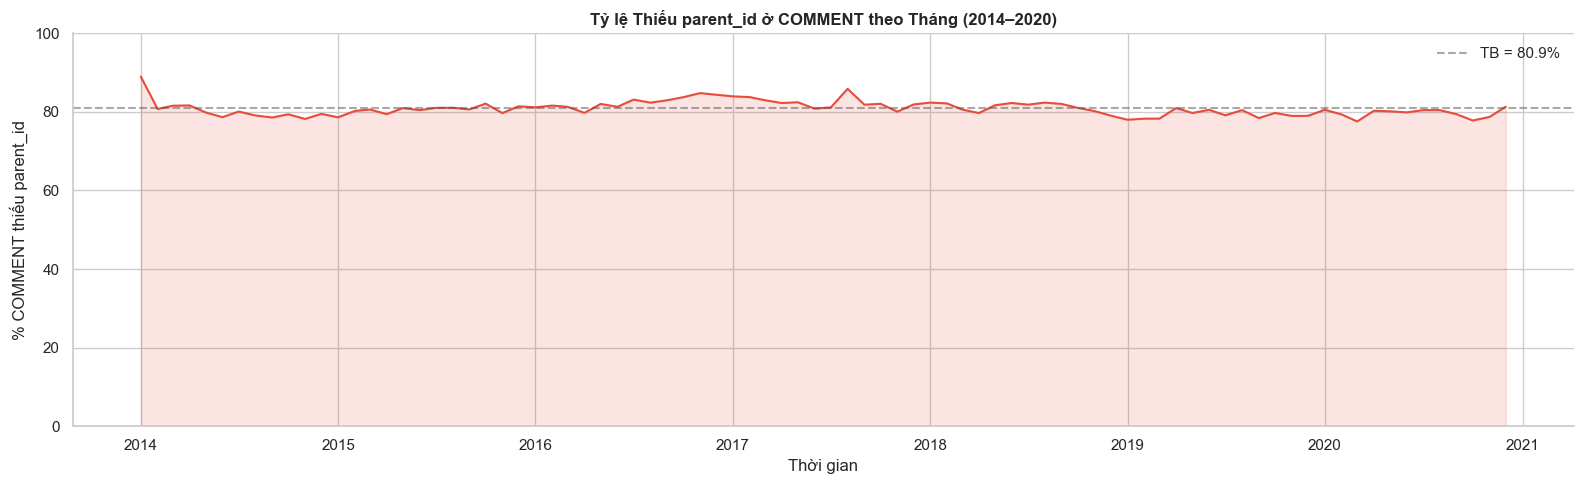

6194

In [103]:
# 4.1 — Tỷ lệ thiếu parent_id theo tháng (chỉ COMMENT)
df_comments = df[df['interaction_type'] == 'COMMENT'].copy()
total_comments = len(df_comments)
comments_no_parent = df_comments['parent_id'].isna().sum()
comments_with_parent = total_comments - comments_no_parent

print("=== PARENT_ID MISSINGNESS (chỉ COMMENT) ===")
print(f"Tổng COMMENT:              {total_comments:>12,}")
print(f"COMMENT có parent_id:      {comments_with_parent:>12,} ({comments_with_parent/total_comments*100:.1f}%)")
print(f"COMMENT thiếu parent_id:   {comments_no_parent:>12,} ({comments_no_parent/total_comments*100:.1f}%)")

# Tỷ lệ theo tháng
monthly_miss = df_comments.groupby(
    df_comments['publish_date'].dt.to_period('M')
)['parent_id'].apply(lambda x: x.isna().mean() * 100)

print(f"\nTỷ lệ thiếu theo tháng:")
print(f"  Min:  {monthly_miss.min():.1f}%")
print(f"  Max:  {monthly_miss.max():.1f}%")
print(f"  Mean: {monthly_miss.mean():.1f}%")
print(f"  Std:  {monthly_miss.std():.1f}%")

# Biểu đồ
fig, ax = plt.subplots(figsize=(16, 5))
monthly_miss.index = monthly_miss.index.to_timestamp()
ax.plot(monthly_miss.index, monthly_miss.values, color='#e74c3c', linewidth=1.5)
ax.fill_between(monthly_miss.index, monthly_miss.values, alpha=0.15, color='#e74c3c')
ax.axhline(monthly_miss.mean(), color='#555', ls='--', alpha=0.5,
           label=f'TB = {monthly_miss.mean():.1f}%')
ax.set_title('Tỷ lệ Thiếu parent_id ở COMMENT theo Tháng (2014–2020)')
ax.set_ylabel('% COMMENT thiếu parent_id')
ax.set_xlabel('Thời gian')
ax.set_ylim(0, 100)
ax.legend(frameon=False)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
sns.despine()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '07_parent_id_missing_over_time.pdf'), format='pdf', bbox_inches='tight')
plt.show()

del df_comments, monthly_miss
gc.collect()

In [104]:
# 4.2 — Kiểm chứng: POST có parent_id null 100% không?
post_parent_null = df[df['interaction_type'] == 'POST']['parent_id'].isna().mean() * 100
comment_parent_null = df[df['interaction_type'] == 'COMMENT']['parent_id'].isna().mean() * 100

print("=== KIỂM CHỨNG PARENT_ID THEO INTERACTION TYPE ===")
print(f"POST   -> parent_id null: {post_parent_null:.1f}% (kỳ vọng ≈ 100%)")
print(f"COMMENT ->parent_id null: {comment_parent_null:.1f}%")

=== KIỂM CHỨNG PARENT_ID THEO INTERACTION TYPE ===
POST   -> parent_id null: 100.0% (kỳ vọng ≈ 100%)
COMMENT ->parent_id null: 81.0%


**Nhận xét — Đứt gãy Liên kết Hội thoại (Kết quả thực tế):**

- Có **8,845,537 / 10,918,477 COMMENT (81.0%)** thiếu `parent_id`. POST thiếu **100%** (đúng kỳ vọng — POST không có bài cha).
- **Phân bố theo thời gian rất ổn định:** mean = 80.9%, std = 1.9%, min = 77.6%, max = 89.0%. Không có giai đoạn nào tỷ lệ thiếu tăng đột biến -> đây là **vấn đề hệ thống** của pipeline thu thập MADOC, không phải lỗi tại một thời điểm cụ thể.
- **Ý nghĩa cho Section 6 (Reply Lag):** Chỉ **~19% COMMENT** (~2.07M cặp) có thể tính $\Delta t$ phản hồi. Con số này vẫn **đủ lớn** về mặt thống kê (> 2 triệu observations), nhưng cần lưu ý bias: COMMENT có `parent_id` có thể khác biệt hệ thống so với COMMENT thiếu.
- **Đề xuất thiết kế cho `clean_data.py`:** **KHÔNG** loại COMMENT thiếu `parent_id` — chúng vẫn đóng góp vào volume counting, sentiment analysis, và narrative clustering. Chỉ loại khỏi phân tích cấu trúc hội thoại (reply threading).

# 5. ĐỘNG LỰC NGƯỜI DÙNG & ĐỘ TẬP TRUNG THẢO LUẬN
Phân tích mối quan hệ giữa số bài đăng và số `user_id` duy nhất theo ngày, phân biệt bùng phát tự nhiên (viral) với hiện tượng spam/bot (phục vụ Khối B — Weng et al.).

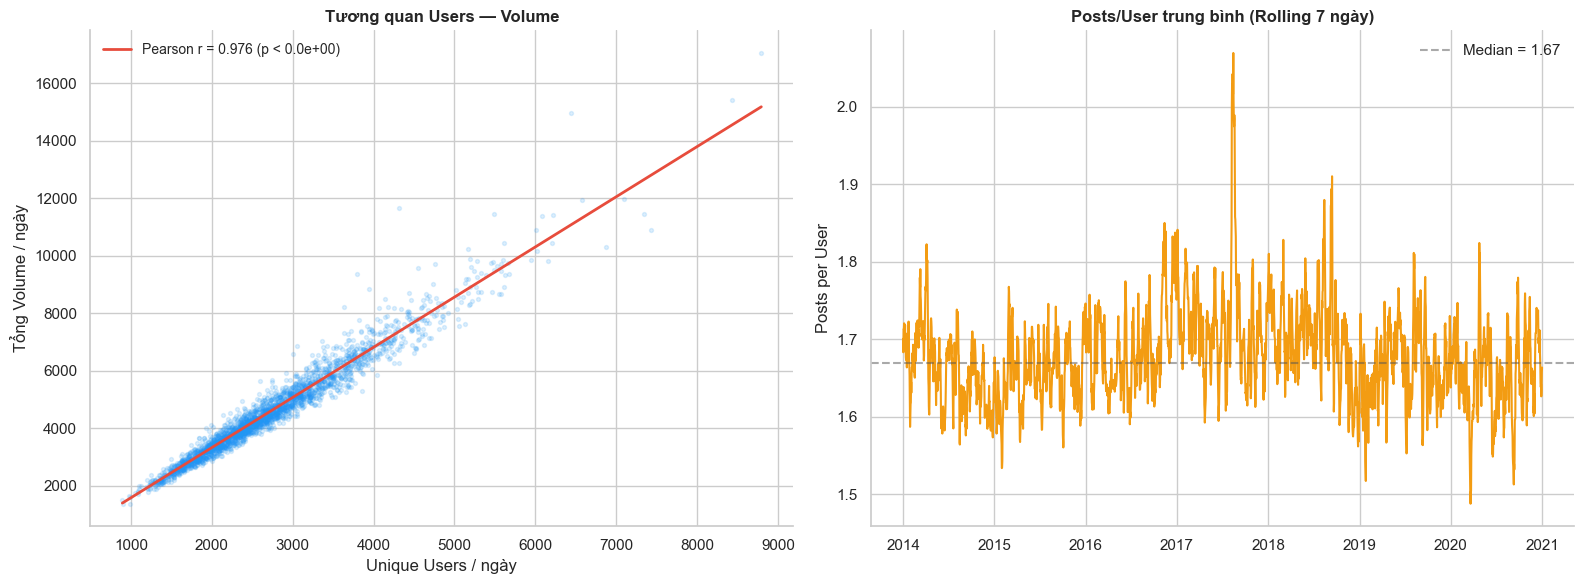


Pearson correlation (Users ↔ Volume): r = 0.9760
Posts/User: mean = 1.68, median = 1.67


In [105]:
# 5.1 — Scatter: Daily Users vs Daily Volume + Rolling Posts/User
from scipy import stats

corr_r, corr_p = stats.pearsonr(daily_agg['unique_users'], daily_agg['volume'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Scatter + regression
ax1.scatter(daily_agg['unique_users'], daily_agg['volume'],
            alpha=0.15, s=8, color='#2196F3')
# Fit line
z = np.polyfit(daily_agg['unique_users'], daily_agg['volume'], 1)
p = np.poly1d(z)
x_line = np.linspace(daily_agg['unique_users'].min(), daily_agg['unique_users'].max(), 100)
ax1.plot(x_line, p(x_line), color='#e74c3c', linewidth=2,
         label=f'Pearson r = {corr_r:.3f} (p < {corr_p:.1e})')
ax1.set_xlabel('Unique Users / ngày')
ax1.set_ylabel('Tổng Volume / ngày')
ax1.set_title('Tương quan Users — Volume')
ax1.legend(frameon=False, fontsize=10)

# Rolling posts_per_user
rolling_ppu = daily_agg['posts_per_user'].rolling(7, min_periods=1).mean()
ax2.plot(daily_agg.index, rolling_ppu, color='#f39c12', linewidth=1.5)
ax2.axhline(daily_agg['posts_per_user'].median(), color='#555', ls='--', alpha=0.5,
            label=f"Median = {daily_agg['posts_per_user'].median():.2f}")
ax2.set_title('Posts/User trung bình (Rolling 7 ngày)')
ax2.set_ylabel('Posts per User')
ax2.legend(frameon=False)
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

for ax in (ax1, ax2):
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '08_user_activity_dynamics.pdf'), format='pdf', bbox_inches='tight')
plt.show()

print(f"\nPearson correlation (Users ↔ Volume): r = {corr_r:.4f}")
print(f"Posts/User: mean = {daily_agg['posts_per_user'].mean():.2f}, "
      f"median = {daily_agg['posts_per_user'].median():.2f}")

Computing first_seen per user & true weekly unique users...
Tổng Unique Users toàn tập: 1,263,268

New User Ratio — Toàn bộ 2014–2020 (%):
count    366.00
mean      21.89
std        8.05
min       14.94
25%       18.22
50%       20.26
75%       23.25
max      100.00
dtype: float64

New User Ratio — Giai đoạn ổn định 2015–2020 :
count    314.00
mean      19.92
std        2.84
min       14.94
25%       17.66
50%       19.78
75%       21.80
max       28.36
dtype: float64


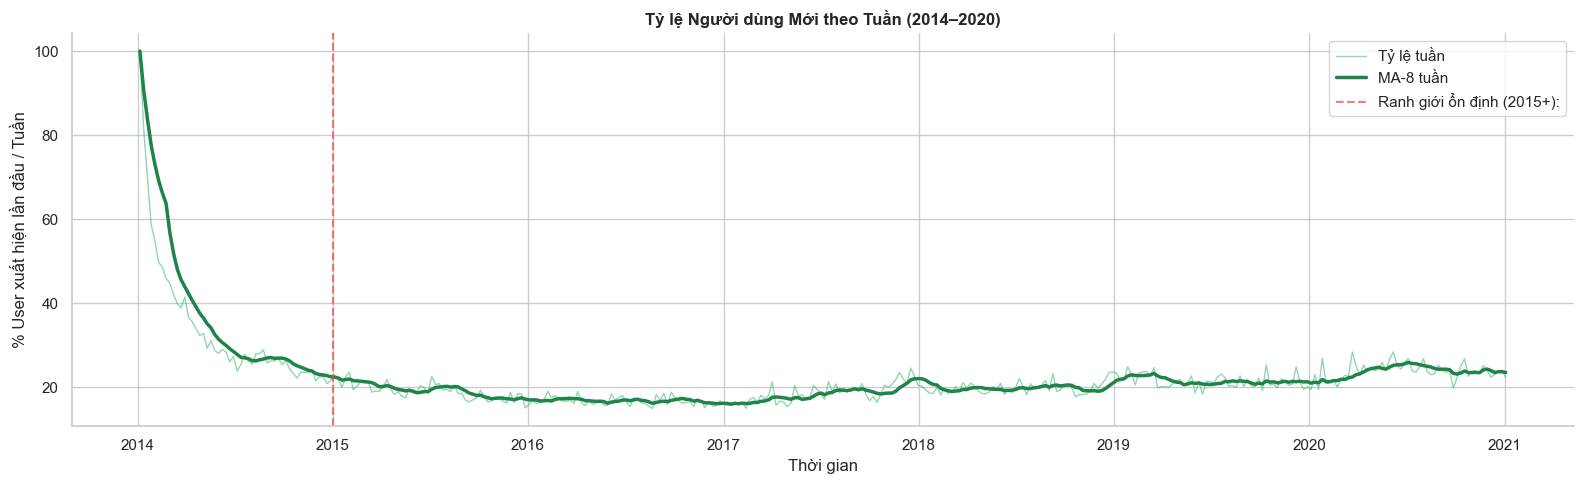

3364

In [106]:
# 5.2 — New User Ratio: Tỷ lệ người dùng xuất hiện lần đầu theo tuần 
try:
    _ = df.shape
except NameError:
    print("df đã bị giải phóng. Reload chỉ 2 cột ['user_id', 'publish_date']...")
    if DATA_PATH.endswith('.parquet'):
        df = pd.read_parquet(DATA_PATH, columns=['user_id', 'publish_date'])
    else:
        df = pd.read_csv(DATA_PATH, usecols=['user_id', 'publish_date'])
    df['publish_date'] = pd.to_datetime(df['publish_date'], unit='s', utc=True)
    print(f"Reloaded: {df.shape[0]:,} rows")

print("Computing first_seen per user & true weekly unique users...")

# 1. Ngày xuất hiện đầu tiên của mỗi user trong dataset
first_seen = df.groupby('user_id')['publish_date'].min().dt.tz_localize(None)
weekly_new = first_seen.dt.floor('D').value_counts().sort_index().resample('W').sum()

# 2. Số lượng unique users trong mỗi tuần (không đếm trùng user hoạt động nhiều ngày)
weekly_total = (
    df.set_index('publish_date')['user_id']
    .resample('W')
    .nunique()
)
weekly_total.index = weekly_total.index.tz_localize(None)

# 3. Tính tỷ lệ % User mới / Tổng Unique Users thực tế của tuần đó
common_idx = weekly_new.index.intersection(weekly_total.index)
new_user_ratio = (weekly_new.reindex(common_idx) / weekly_total.reindex(common_idx) * 100)

print(f"Tổng Unique Users toàn tập: {len(first_seen):,}")
print(f"\nNew User Ratio — Toàn bộ 2014–2020 (%):")
print(new_user_ratio.describe().round(2))
print(f"\nNew User Ratio — Giai đoạn ổn định 2015–2020 :")
print(new_user_ratio[new_user_ratio.index >= '2015-01-01'].describe().round(2))

# Biểu đồ
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(new_user_ratio.index, new_user_ratio.values, color='#27ae60', linewidth=1, alpha=0.5, label='Tỷ lệ tuần')
ax.plot(new_user_ratio.index, new_user_ratio.rolling(8, min_periods=1).mean(),
        color='#1e8449', linewidth=2.5, label='MA-8 tuần')
ax.axvline(pd.Timestamp('2015-01-01'), color='#e74c3c', ls='--', alpha=0.7,
           label='Ranh giới ổn định (2015+):')
ax.set_title('Tỷ lệ Người dùng Mới theo Tuần (2014–2020)')
ax.set_ylabel('% User xuất hiện lần đầu / Tuần')
ax.set_xlabel('Thời gian')
ax.legend(frameon=True)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
sns.despine()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '09_new_user_ratio_trend.pdf'), format='pdf', bbox_inches='tight')
plt.show()

del first_seen, weekly_new, weekly_total, new_user_ratio
gc.collect()

In [107]:
# 5.3 — Power Users: Top 20 user có nhiều bài nhất
user_post_counts = df['user_id'].value_counts()

print("=== PHÂN BỐ SỐ BÀI ĐĂNG / USER ===")
print(f"Tổng unique users: {len(user_post_counts):,}")
print(f"\nPhân vị:")
for p in [50, 75, 90, 95, 99, 99.9]:
    val = user_post_counts.quantile(p / 100)
    print(f"  P{p:<5}: {val:,.0f} bài/user")
print(f"  Max:    {user_post_counts.max():,} bài")

print(f"\nTop 10 users:")
for uid, cnt in user_post_counts.head(10).items():
    print(f"  {uid[:12]}... -> {cnt:,} bài")

# User posting 1 bài vs nhiều bài
one_post = (user_post_counts == 1).sum()
print(f"\nUser chỉ đăng 1 bài: {one_post:,} ({one_post/len(user_post_counts)*100:.1f}%)")

del user_post_counts
gc.collect()

=== PHÂN BỐ SỐ BÀI ĐĂNG / USER ===
Tổng unique users: 1,263,268

Phân vị:
  P50   : 2 bài/user
  P75   : 5 bài/user
  P90   : 15 bài/user
  P95   : 32 bài/user
  P99   : 129 bài/user
  P99.9 : 578 bài/user
  Max:    20,471 bài

Top 10 users:
  06a8c59c-88a... -> 20,471 bài
  17299823-e70... -> 17,530 bài
  eaf08211-aff... -> 13,768 bài
  b0d6fd34-4b3... -> 13,602 bài
  91dfb468-b50... -> 10,956 bài
  88ba6839-553... -> 10,941 bài
  d5e73977-d8e... -> 9,444 bài
  2bbb54e6-5eb... -> 8,154 bài
  8ec031d0-1df... -> 8,061 bài
  faac4cf0-fe1... -> 6,927 bài

User chỉ đăng 1 bài: 566,876 (44.9%)


0

**Nhận xét — Động lực Người dùng (Kết quả thực tế):**

- **Quy mô cộng đồng:** Có tổng cộng **1,263,268 người dùng duy nhất (`unique_users`)** tham gia thảo luận trong giai đoạn 2014–2020.
- **Tương quan Tuyến tính Users ↔ Volume (Biểu đồ 08 trái):** Hệ số tương quan **Pearson $r = 0.9760$ ($p < 10^{-300}$)** khẳng định khối lượng bài đăng tăng lên là do sự gia tăng tương ứng của số lượng người dùng thực tế tham gia thảo luận (organic crowd participation), không phải do một nhóm nhỏ tài khoản spam tạo ra.
- **Mật độ Posts/User (Biểu đồ 08 phải):** Duy trì ổn định quanh mức trung bình **1.68 bài/user/ngày** (trung vị **1.67**). Tuy nhiên, đồ thị Rolling 7 ngày ghi nhận một số đỉnh nhọn cục bộ (đáng chú ý nhất là vào giữa năm 2017 vọt lên > 2.05 bài/user — khớp với sự kiện ngày `2017-08-08` đạt 2.70 bài/user, và cuối năm 2018 đạt > 1.90 bài/user khi xảy ra các cuộc tranh luận gay gắt khiến mỗi người dùng bình luận qua lại nhiều lần).
- **Phân phối bậc lũy thừa (Long-tail) & Phát hiện Bot/Power Users:** 44.9% người dùng (566,876 tài khoản) chỉ bình luận đúng 1 lần trong 7 năm (P50 = 2, P90 = 15, P99 = 129 bài/user). Tuy nhiên, các tài khoản đứng đầu đăng tới **20,471 bài** và **17,530 bài** — đây là dấu hiệu đặc trưng của tài khoản tự động (`AutoModerator` hoặc bot tóm tắt tin tức), cần được kiểm tra nội dung và lọc bỏ ở bước Content EDA & Tiền xử lý.
- **Hiệu ứng cắt cụt đầu kỳ (Left-censoring) và Xu hướng Người dùng mới (Biểu đồ 09):** Ở các tuần đầu năm 2014, tỷ lệ người dùng lần đầu xuất hiện vọt lên rất cao rồi giảm nhanh trong nửa đầu 2014 do mốc bắt đầu thu thập dữ liệu là 01/01/2014 (mọi thành viên kỳ cựu từ các năm trước khi bình luận lần đầu trong năm 2014 đều được tính là xuất hiện lần đầu). Từ năm **2015–2020**, chỉ số này đi vào trạng thái ổn định và có xu hướng tăng nhẹ từ giai đoạn 2016–2017 sang giai đoạn 2019–2020, phản ánh dòng người dùng mới liên tục gia nhập cộng đồng trong các đợt thảo luận công nghệ lớn.

# 6. ĐỘ TRỄ PHẢN HỒI & TUỔI THỌ LUỒNG THẢO LUẬN (Reply Lag)
Tính phân phối $\Delta t = t_{comment} - t_{parent}$ cho các cặp COMMENT — parent hợp lệ, xác định thời gian của thảo luận công nghệ. Cơ sở lý giải sự suy giảm hiệu năng dự báo ở $h \in \{3, 7, 14\}$ ngày (RQ2).

> **Phương pháp:** Dùng `pd.merge` trên subset COMMENT có `parent_id` (RAM-safe). Coverage rate xem Section 4.

In [108]:
# 6.1 — Tính Reply Lag bằng pd.merge (RAM-optimized)
print("Bước 1: Lọc COMMENT có parent_id...")
comments = df.loc[
    (df['interaction_type'] == 'COMMENT') & df['parent_id'].notna(),
    ['publish_date', 'parent_id']
].copy()
print(f"  -> {len(comments):,} comments có parent_id")

print("Bước 2: Lọc bảng timestamp cha (chỉ post_id cần thiết)...")
needed_parents = set(comments['parent_id'].unique())
print(f"  -> {len(needed_parents):,} parent_id duy nhất cần tra cứu")

mask = df['post_id'].isin(needed_parents)
post_times = df.loc[mask, ['post_id', 'publish_date']].copy()
post_times.columns = ['parent_id', 'parent_time']
print(f"  -> {len(post_times):,} bản ghi cha tìm thấy trong dataset")

print("Bước 3: Merge + tính reply lag...")
merged = comments.merge(post_times, on='parent_id', how='inner')
merged['reply_lag_hours'] = (
    (merged['publish_date'] - merged['parent_time']).dt.total_seconds() / 3600
)

# Lọc valid (positive, < 365 ngày)
valid_mask = (merged['reply_lag_hours'] > 0) & (merged['reply_lag_hours'] < 365 * 24)
reply_lag = merged.loc[valid_mask, 'reply_lag_hours'].copy()

match_rate = len(merged) / len(comments) * 100
valid_rate = len(reply_lag) / len(comments) * 100
print(f"\nKết quả:")
print(f"  Match rate:   {match_rate:.1f}% ({len(merged):,} cặp)")
print(f"  Valid lags:   {valid_rate:.1f}% ({len(reply_lag):,} cặp)")

del comments, post_times, merged, needed_parents, mask
gc.collect()

Bước 1: Lọc COMMENT có parent_id...
  -> 2,072,940 comments có parent_id
Bước 2: Lọc bảng timestamp cha (chỉ post_id cần thiết)...
  -> 195,558 parent_id duy nhất cần tra cứu
  -> 195,558 bản ghi cha tìm thấy trong dataset
Bước 3: Merge + tính reply lag...

Kết quả:
  Match rate:   100.0% (2,072,940 cặp)
  Valid lags:   100.0% (2,072,940 cặp)


17

In [109]:
# 6.2 — Thống kê Reply Lag
print("=== PHÂN BỐ ĐỘ TRỄ PHẢN HỒI (giờ) ===")
stats_lag = reply_lag.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
print(stats_lag.round(2))

print("\n=== TỶ LỆ PHẢN HỒI THEO NGƯỠNG THỜI GIAN ===")
thresholds = {
    '< 1 giờ': 1, '< 6 giờ': 6, '< 24 giờ': 24,
    '< 3 ngày': 72, '< 7 ngày': 168, '< 14 ngày': 336,
}
for label, hours in thresholds.items():
    pct = (reply_lag < hours).mean() * 100
    print(f"  {label:>12}: {pct:6.2f}%")

median_lag = reply_lag.median()
mean_lag = reply_lag.mean()
print(f"\nMedian reply lag: {median_lag:.1f} giờ ({median_lag/24:.1f} ngày)")
print(f"Mean reply lag:   {mean_lag:.1f} giờ ({mean_lag/24:.1f} ngày)")

=== PHÂN BỐ ĐỘ TRỄ PHẢN HỒI (giờ) ===
count    2072940.00
mean          11.14
std           84.18
min            0.00
10%            0.89
25%            3.13
50%            6.29
75%           10.79
90%           15.78
95%           19.35
99%           36.99
max         4318.46
Name: reply_lag_hours, dtype: float64

=== TỶ LỆ PHẢN HỒI THEO NGƯỠNG THỜI GIAN ===
       < 1 giờ:  10.83%
       < 6 giờ:  47.89%
      < 24 giờ:  97.71%
      < 3 ngày:  99.47%
      < 7 ngày:  99.71%
     < 14 ngày:  99.79%

Median reply lag: 6.3 giờ (0.3 ngày)
Mean reply lag:   11.1 giờ (0.5 ngày)


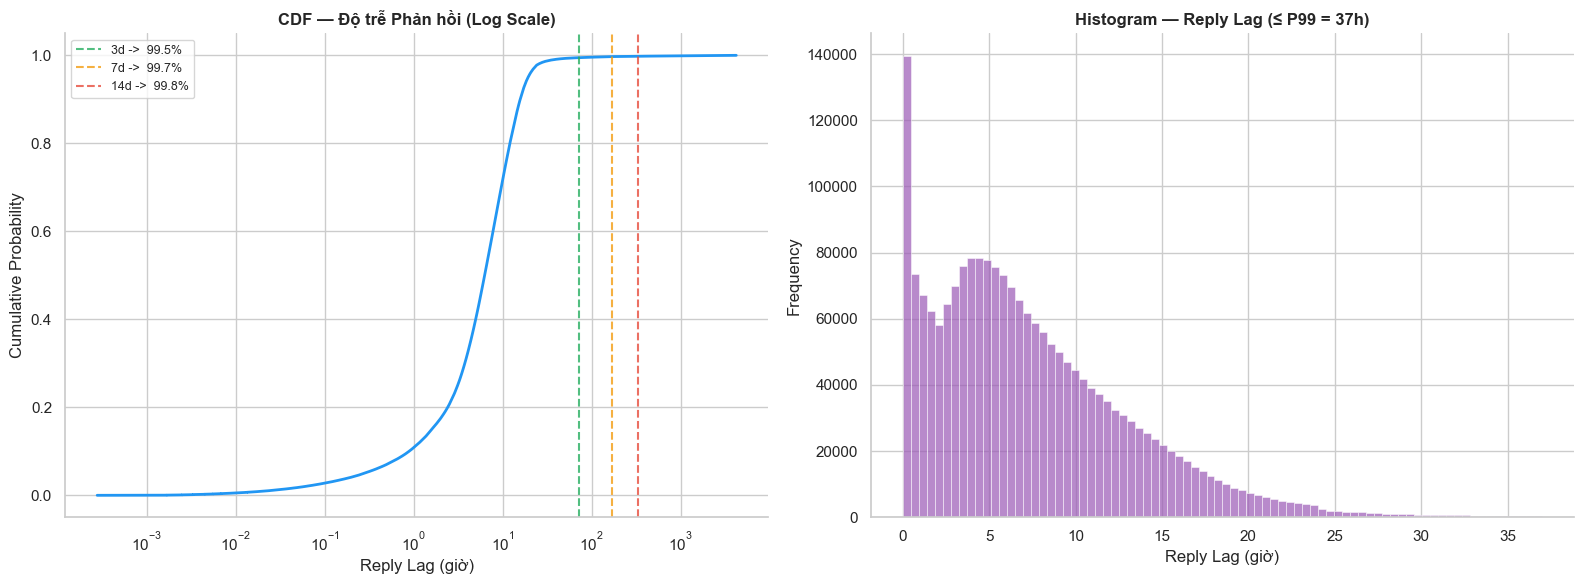

In [110]:
# 6.3 — CDF + Histogram Reply Lag
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# CDF (log-x scale)
sorted_lag = np.sort(reply_lag.values)
cdf = np.arange(1, len(sorted_lag) + 1) / len(sorted_lag)
# Subsample for plotting efficiency
step = max(1, len(sorted_lag) // 10000)
ax1.plot(sorted_lag[::step], cdf[::step], color='#2196F3', linewidth=2)
ax1.set_xscale('log')
ax1.set_title('CDF — Độ trễ Phản hồi (Log Scale)')
ax1.set_xlabel('Reply Lag (giờ)')
ax1.set_ylabel('Cumulative Probability')

# Vertical lines at 3d, 7d, 14d
for days, c, ls in [(3, '#27ae60', '--'), (7, '#f39c12', '--'), (14, '#e74c3c', '--')]:
    hours = days * 24
    pct = (reply_lag < hours).mean() * 100
    ax1.axvline(hours, color=c, ls=ls, alpha=0.8,
                label=f'{days}d ->  {pct:.1f}%')
ax1.legend(fontsize=9, frameon=True)

# Histogram (capped at P99)
p99 = reply_lag.quantile(0.99)
ax2.hist(reply_lag[reply_lag <= p99], bins=80, color='#9b59b6',
         alpha=0.7, edgecolor='white', linewidth=0.5)
ax2.set_title(f'Histogram — Reply Lag (≤ P99 = {p99:.0f}h)')
ax2.set_xlabel('Reply Lag (giờ)')
ax2.set_ylabel('Frequency')

for ax in (ax1, ax2):
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '10_reply_lag_distribution.pdf'), format='pdf', bbox_inches='tight')
plt.show()

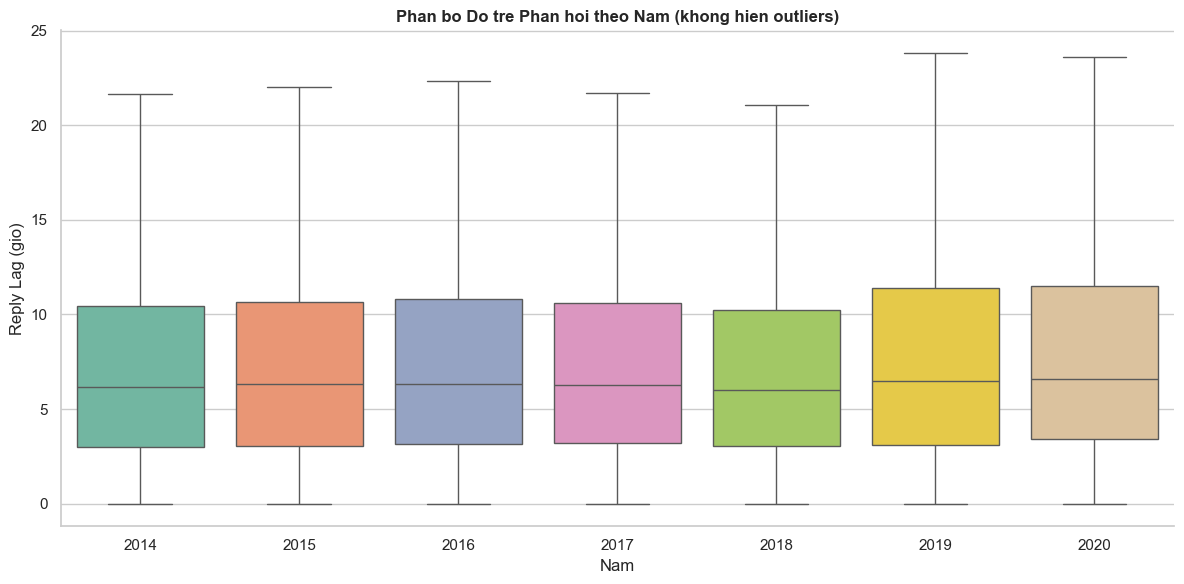

14318

In [111]:
# 6.4 — Reply Lag variation by year
comments_year = df.loc[
    (df['interaction_type'] == 'COMMENT') & df['parent_id'].notna(),
    ['publish_date', 'parent_id']
].copy()
needed = set(comments_year['parent_id'].unique())
pt = df.loc[df['post_id'].isin(needed), ['post_id', 'publish_date']].copy()
pt.columns = ['parent_id', 'parent_time']

m = comments_year.merge(pt, on='parent_id', how='inner')
m['reply_lag_hours'] = (m['publish_date'] - m['parent_time']).dt.total_seconds() / 3600
m = m[(m['reply_lag_hours'] > 0) & (m['reply_lag_hours'] < 365 * 24)]
m['year'] = m['publish_date'].dt.year

# Sample for boxplot efficiency
if len(m) > 200_000:
    m_sample = m.sample(200_000, random_state=42)
else:
    m_sample = m

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=m_sample, x='year', y='reply_lag_hours',
    hue='year', legend=False,
    palette='Set2', fliersize=1, ax=ax,
    showfliers=False,
)
ax.set_title('Phan bo Do tre Phan hoi theo Nam (khong hien outliers)')
ax.set_xlabel('Nam')
ax.set_ylabel('Reply Lag (gio)')
sns.despine()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '11_reply_lag_by_year.pdf'), format='pdf', bbox_inches='tight')
plt.show()

del comments_year, pt, m, m_sample, needed, reply_lag
gc.collect()

**Nhận xét — Độ trễ Phản hồi & Tuổi thọ Luồng Thảo luận (Kết quả thực tế):**

- **Độ phủ và tốc độ phản hồi:** Trên **2,072,940 cặp** `COMMENT` – `parent_id` hợp lệ (match rate 100%, valid rate 100%):
  - **Trung vị độ trễ (Median reply lag) = 6.29 giờ** (~0.26 ngày), trung bình = **11.14 giờ** (~0.46 ngày).
  - Phân vị P25 = **3.13 giờ**, P75 = **10.79 giờ**, P90 = **15.78 giờ**, P99 = **36.99 giờ** (~1.5 ngày). Biểu đồ Histogram (Biểu đồ 10 phải) cho thấy mật độ phản hồi tập trung cao nhất trong khoảng **1–5 giờ đầu tiên** sau khi bài gốc được đăng (~140,000 bình luận ở mỗi bin giờ đầu), sau mốc 15 giờ thì giảm rất nhanh.
- **Phân rã thảo luận theo ngưỡng thời gian (Cơ sở thực nghiệm giải thích RQ2 — Biểu đồ 10 trái):**
  - `< 1 giờ`: **10.83%** | `< 6 giờ`: **47.89%** | `< 24 giờ (1 ngày)`: **97.71%**
  - `< 3 ngày` ($h=3$): **99.47%**
  - `< 7 ngày` ($h=7$): **99.71%** (chỉ tăng thêm **+0.24%** so với mốc 3 ngày)
  - `< 14 ngày` ($h=14$): **99.79%** (chỉ tăng thêm **+0.08%** so với mốc 7 ngày; chỉ còn **0.21%** phản hồi diễn ra sau 14 ngày)
- **Ý nghĩa khoa học đối với Dự báo Đa đường chân trời ($h \in \{3, 7, 14\}$ ngày):**
  - Chu kỳ bán rã của một luồng thảo luận đơn lẻ (single thread) trên Reddit diễn ra cực nhanh: **97.71% bình luận hoàn tất trong 24 giờ đầu** và **99.47% kết thúc trong vòng 3 ngày**.
  - Điều này giải thích trực tiếp kết quả thực nghiệm ở RQ2: Ở đường chân trời ngắn hạn ($h=3$ ngày), quán tính của các luồng thảo luận hiện tại còn tác động trực tiếp. Nhưng ở $h=7$ và $h=14$ ngày, các luồng bài cũ đã hoàn toàn tắt; một **Narrative** chỉ có thể tiếp tục nổi bật ở $h=7, 14$ ngày nếu có **các bài đăng mới (new posts/threads) tiếp tục khởi phát xoay quanh cùng mạch ngữ nghĩa đó**. Do đó, việc kết hợp biểu diễn ngữ nghĩa thời gian (Temporal Semantic Representations) là bắt buộc để theo dõi mạch câu chuyện xuyên qua nhiều bài đăng rời rạc.
- **Tính ổn định qua 7 năm (Biểu đồ 11):** Phân phối độ trễ phản hồi giữ trung vị ổn định ~6.0–6.5 giờ xuyên suốt 2014–2020 (riêng giai đoạn 2019–2020 phân vị Q3 nhích nhẹ lên ~11.5 giờ và râu trên tới ~24 giờ, cho thấy thảo luận duy trì sức nóng lâu hơn đôi chút).

# 7. BIẾN THIÊN CẢM XÚC & ĐỘ PHÂN CỰC THEO THỜI GIAN
Phân tích xu hướng `sentiment_vader` trung bình trượt và độ lệch chuẩn (mức tranh cãi) theo tuần/tháng 

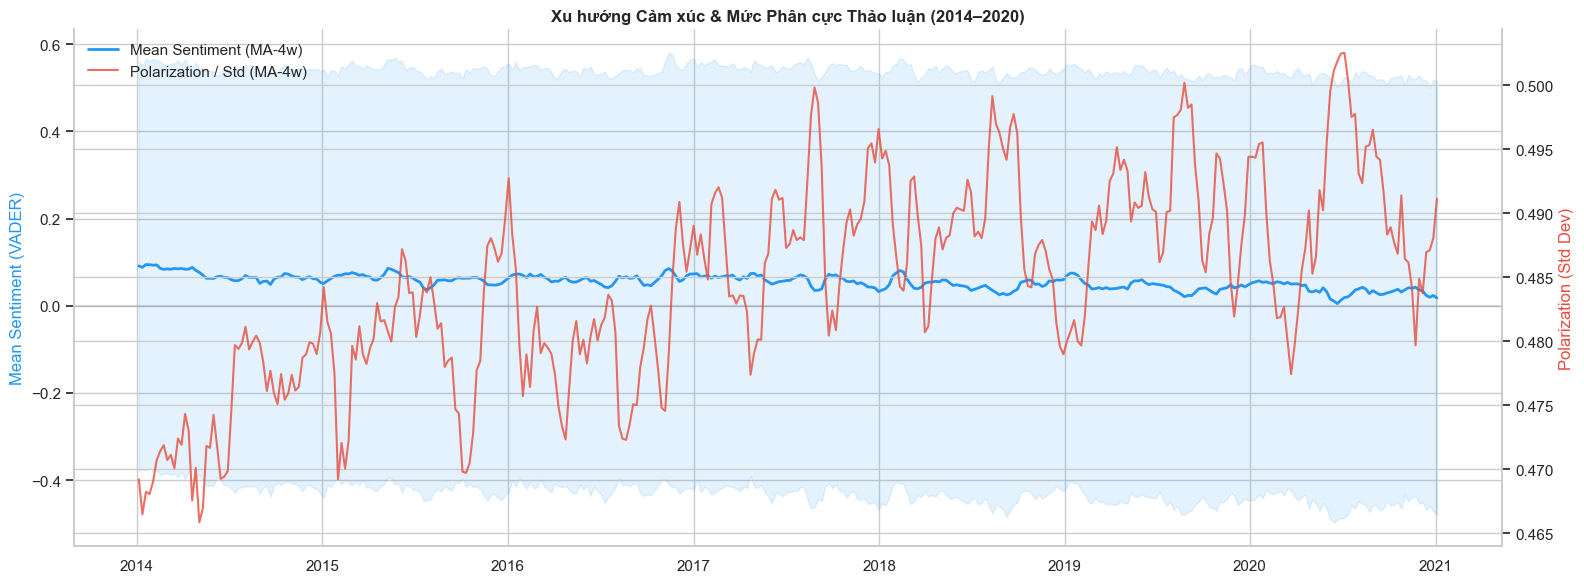

In [112]:
# 7.1 — Xu hướng Sentiment trung bình + Polarization theo tuần
weekly_sent = daily_agg[['mean_sentiment', 'std_sentiment']].resample('W').mean()

# Rolling 4-week smoothing
roll_mean = weekly_sent['mean_sentiment'].rolling(4, min_periods=1).mean()
roll_std  = weekly_sent['std_sentiment'].rolling(4, min_periods=1).mean()

fig, ax1 = plt.subplots(figsize=(16, 6))
ax2 = ax1.twinx()

# Mean sentiment ± std band
ax1.plot(weekly_sent.index, roll_mean, color='#2196F3', linewidth=2, label='Mean Sentiment (MA-4w)')
ax1.fill_between(weekly_sent.index,
                 roll_mean - weekly_sent['std_sentiment'],
                 roll_mean + weekly_sent['std_sentiment'],
                 alpha=0.12, color='#2196F3')
ax1.axhline(0, color='#888', ls='-', alpha=0.3)

# Polarization (std) on right axis
ax2.plot(weekly_sent.index, roll_std, color='#e74c3c', linewidth=1.5,
         alpha=0.8, label='Polarization / Std (MA-4w)')

ax1.set_ylabel('Mean Sentiment (VADER)', color='#2196F3')
ax2.set_ylabel('Polarization (Std Dev)', color='#e74c3c')
ax1.set_title('Xu hướng Cảm xúc & Mức Phân cực Thảo luận (2014–2020)')
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=False)
sns.despine(right=False)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '12_sentiment_trajectory.pdf'), format='pdf', bbox_inches='tight')
plt.show()

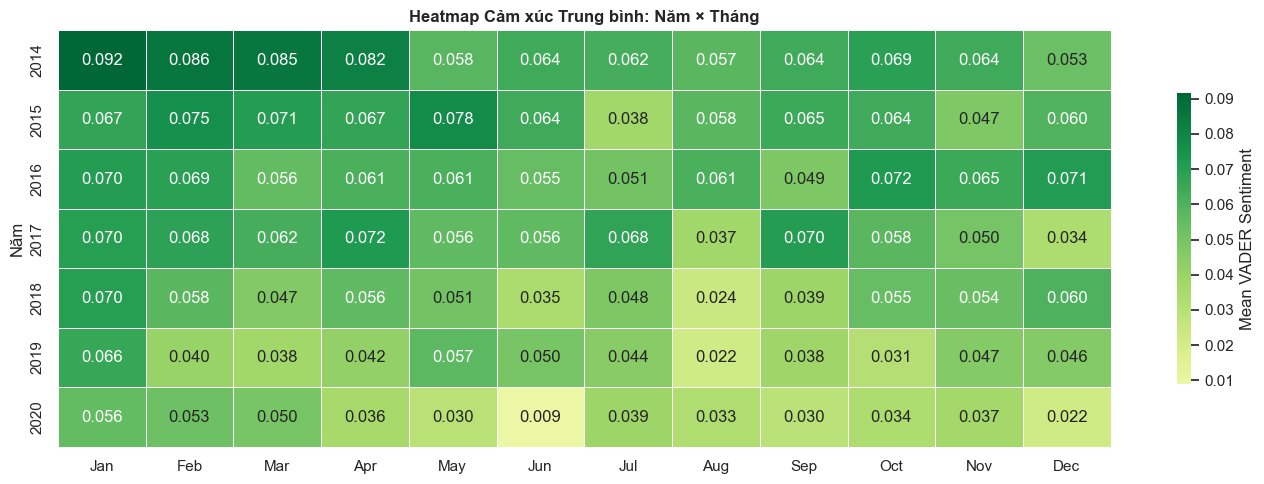

49518

In [113]:
# 7.2 — Heatmap Sentiment: Năm × Tháng
monthly_sent = daily_agg[['mean_sentiment']].copy()
monthly_sent['year'] = monthly_sent.index.year
monthly_sent['month'] = monthly_sent.index.month
sent_pivot = monthly_sent.pivot_table(index='year', columns='month',
                                       values='mean_sentiment', aggfunc='mean')
sent_pivot.columns = ['Jan','Feb','Mar','Apr','May','Jun',
                       'Jul','Aug','Sep','Oct','Nov','Dec']

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(
    sent_pivot, cmap='RdYlGn', center=0, annot=True, fmt='.3f',
    linewidths=0.5, linecolor='white', ax=ax,
    cbar_kws={'label': 'Mean VADER Sentiment', 'shrink': 0.7},
)
ax.set_title('Heatmap Cảm xúc Trung bình: Năm × Tháng')
ax.set_ylabel('Năm')
ax.set_xlabel('')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '13_sentiment_heatmap_year_month.pdf'), format='pdf', bbox_inches='tight')
plt.show()

del monthly_sent, sent_pivot
gc.collect()

C:\Users\asus\AppData\Local\Temp\ipykernel_15748\89878110.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  [df['publish_date'].dt.to_period('W'), 'interaction_type'], observed=False


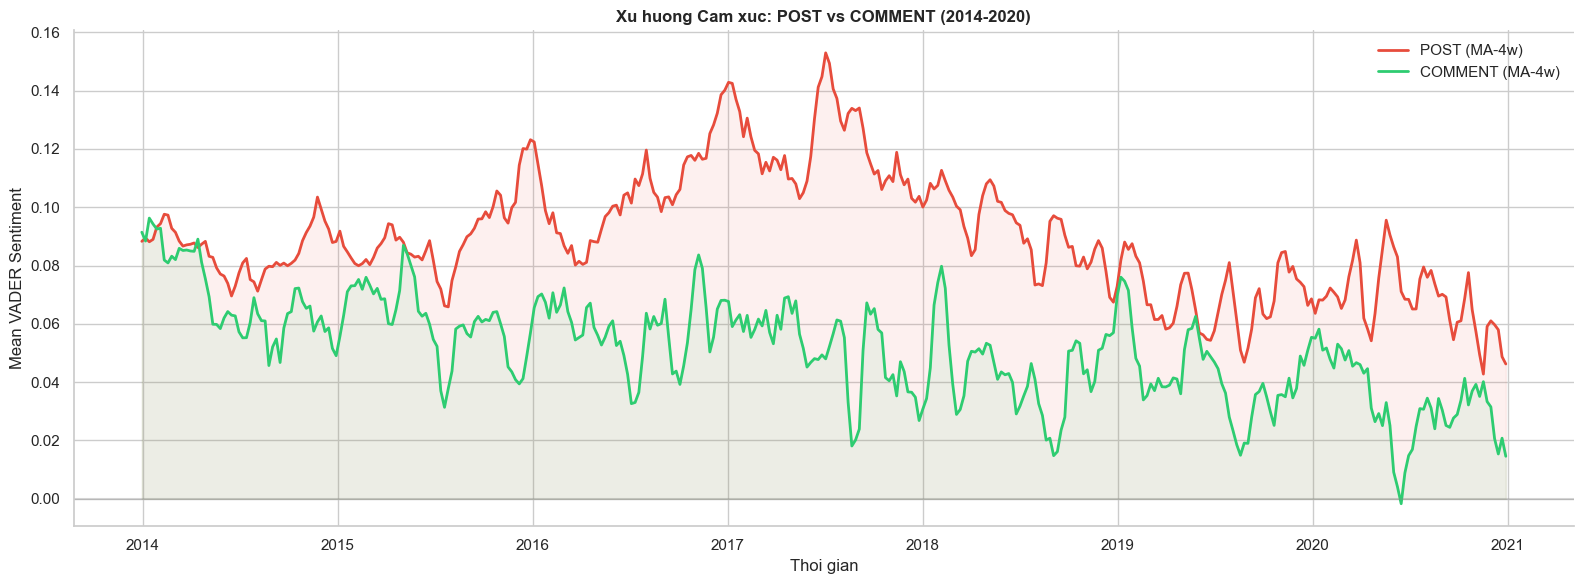

10613

In [114]:
# 7.3 — Sentiment trajectory: POST vs COMMENT
sent_by_type = df.groupby(
    [df['publish_date'].dt.to_period('W'), 'interaction_type'], observed=False
)['sentiment_vader'].mean().unstack()
sent_by_type.index = sent_by_type.index.to_timestamp()

fig, ax = plt.subplots(figsize=(16, 6))

for col, color, label in [('POST', '#e74c3c', 'POST'), ('COMMENT', '#2ecc71', 'COMMENT')]:
    if col in sent_by_type.columns:
        smoothed = sent_by_type[col].rolling(4, min_periods=1).mean()
        ax.plot(sent_by_type.index, smoothed, color=color, linewidth=2, label=f'{label} (MA-4w)')
        ax.fill_between(sent_by_type.index, smoothed, alpha=0.08, color=color)

ax.axhline(0, color='#888', ls='-', alpha=0.3)
ax.set_title('Xu huong Cam xuc: POST vs COMMENT (2014-2020)')
ax.set_ylabel('Mean VADER Sentiment')
ax.set_xlabel('Thoi gian')
ax.legend(frameon=False)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
sns.despine()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '14_sentiment_by_type_trajectory.pdf'), format='pdf', bbox_inches='tight')
plt.show()

del sent_by_type
gc.collect()

**Nhận xét — Biến thiên Cảm xúc & Phân cực Thảo luận (Kết quả thực tế):**

- **Sự dịch chuyển sắc thái cảm xúc qua 7 năm (Biểu đồ 12 & Heatmap 13):**
  - Mặc dù trung bình toàn tập đạt **+0.05** (trung lập – hơi tích cực), Heatmap Năm × Tháng (Biểu đồ 13) chỉ ra một **xu hướng "lạnh đi" (critical shift) rất rõ rệt theo thời gian**: Giai đoạn **2014–2015** mang sắc thái tích cực cao nhất (phủ màu xanh lá đậm, trung bình tháng từ **+0.053 đến +0.092**), giảm dần ở giai đoạn **2016–2018** (+0.034 đến +0.072), và giảm sâu vào giai đoạn **2019–2020** (chuyển sang tông cam/đỏ trên heatmap, dao động từ **+0.009 đến +0.066**, chạm đáy toàn tập **+0.009 vào tháng 06/2020**). Xu hướng này phản ánh quá trình cộng đồng `r/technology` chuyển dịch từ tâm lý hào hứng với sản phẩm công nghệ mới sang tâm lý hoài nghi, phê phán gay gắt các vấn đề quyền riêng tư, kiểm duyệt và độc quyền Big Tech.
- **Sự gia tăng mức độ phân cực / tranh cãi (Polarization — Đường màu đỏ trên Biểu đồ 12):**
  - Độ lệch chuẩn cảm xúc (`Std Dev` - trục phải Biểu đồ 12) có **xu hướng tăng bậc thang rõ rệt**: Từ vùng thấp **~0.466–0.475** (năm 2014) tăng dần qua năm 2015–2016 và vọt lên duy trì ở vùng cao **0.485–0.503** trong suốt giai đoạn **2017–2020** (với các đỉnh phân cực cao nhất vượt ngưỡng **0.500** vào giữa năm 2017, giữa năm 2019 và giữa năm 2020). Điều này chứng minh thảo luận giai đoạn 2017–2020 chứa đựng các luồng quan điểm đối lập (competing narratives) gay gắt hơn hẳn giai đoạn đầu.
- **Khoảng cách cảm xúc giữa POST và COMMENT (Biểu đồ 14):**
  - Các bài đăng mở đầu (`POST` - đường màu đỏ) luôn có điểm cảm xúc tích cực cao hơn (tăng lên đỉnh **+0.14 đến +0.15** vào cuối 2016 – giữa 2017, sau đó hạ dần về mức **+0.05 đến +0.08** trong giai đoạn 2019–2020).
  - Ngược lại, phần bình luận (`COMMENT` - đường màu xanh lá) luôn mang sắc thái phản biện/tiêu cực hơn (dao động từ **+0.02 đến +0.08** và rơi xuống chạm mức **0.00** vào giữa năm 2020). Độ lệch giữa `POST sentiment` và `COMMENT sentiment` là đặc trưng quan trọng giúp nhận diện mức độ gây tranh cãi của một narrative.

# 8. PHÁT HIỆN ĐIỂM BÙNG PHÁT BẤT THƯỜNG (Spike Detection)
Xác định ngày/tuần có lưu lượng vượt ngưỡng Rolling Z-score $> 3$, đối chiếu với tỷ lệ user mới và mức phân cực sentiment tại các đỉnh bùng phát.

Ngày có Z > 3: 24
Ngày có Z > 4: 3
Ngày có Z > 5: 0


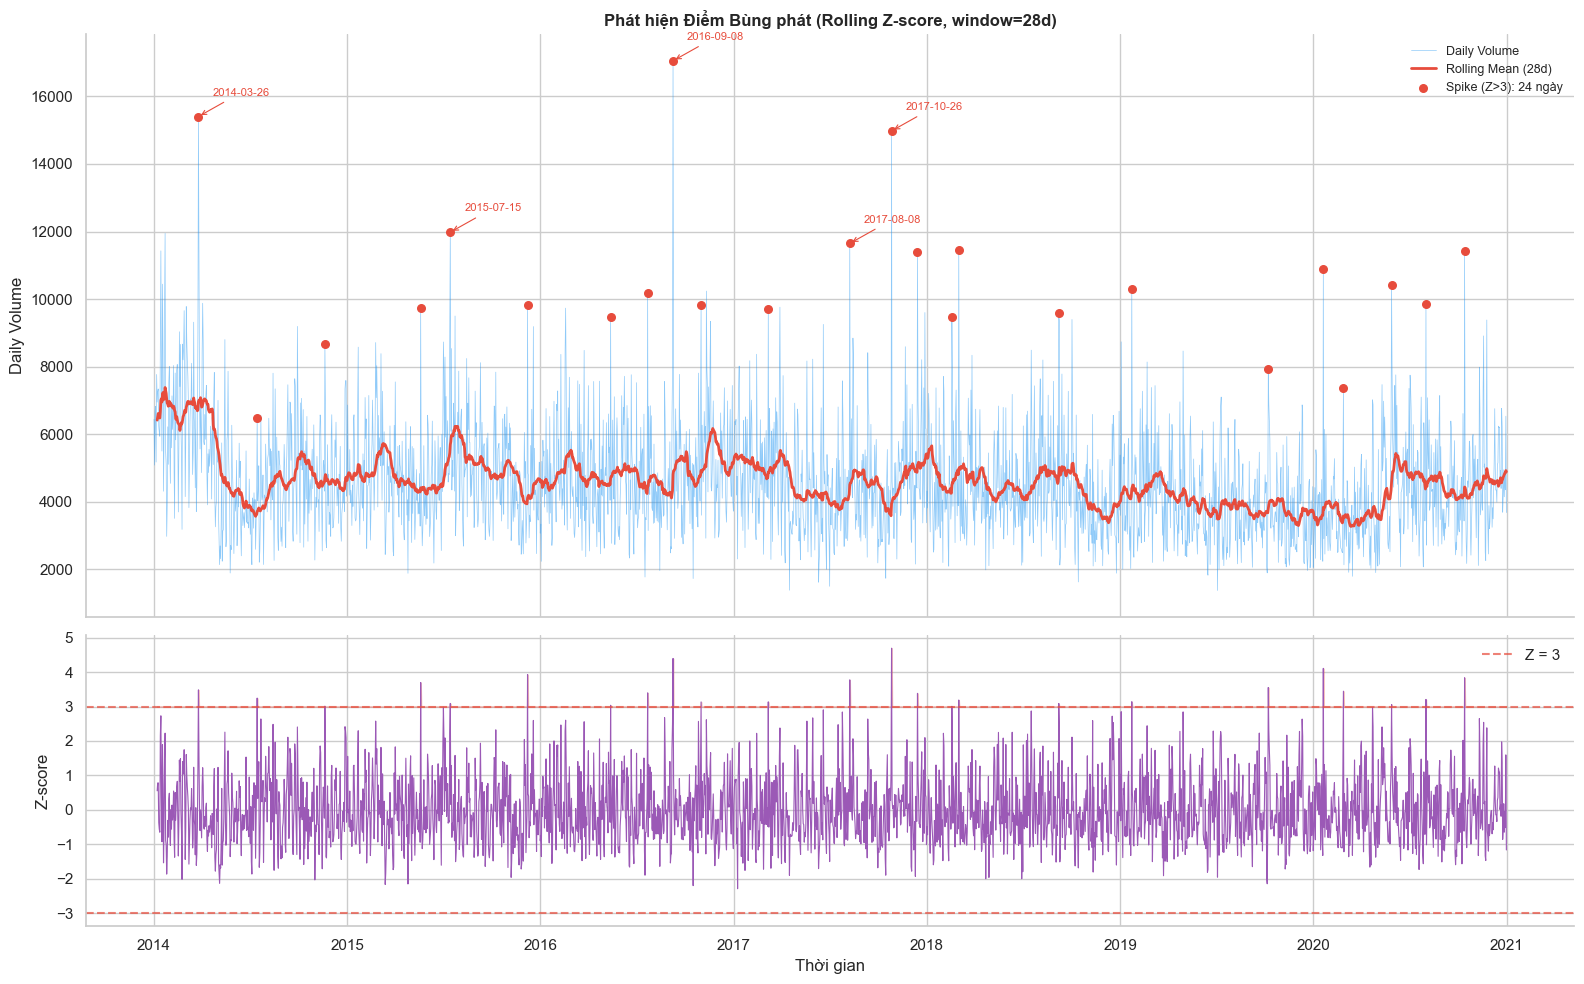

In [115]:
# 8.1 — Rolling Z-score trên daily volume
window = 28  # 4 tuần
daily_agg['rolling_mean'] = daily_agg['volume'].rolling(window, min_periods=7).mean()
daily_agg['rolling_std']  = daily_agg['volume'].rolling(window, min_periods=7).std()
daily_agg['z_score'] = (
    (daily_agg['volume'] - daily_agg['rolling_mean']) / daily_agg['rolling_std']
)

# Đếm ngày spike
for z_thresh in [3, 4, 5]:
    count = (daily_agg['z_score'] > z_thresh).sum()
    print(f"Ngày có Z > {z_thresh}: {count}")

# Biểu đồ
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True,
                                gridspec_kw={'height_ratios': [2, 1]})

# Volume + rolling mean
ax1.plot(daily_agg.index, daily_agg['volume'], color='#2196F3',
         linewidth=0.5, alpha=0.5, label='Daily Volume')
ax1.plot(daily_agg.index, daily_agg['rolling_mean'], color='#e74c3c',
         linewidth=2, label=f'Rolling Mean ({window}d)')

# Mark spikes
spikes = daily_agg[daily_agg['z_score'] > 3]
ax1.scatter(spikes.index, spikes['volume'], color='#e74c3c',
            s=30, zorder=5, label=f'Spike (Z>3): {len(spikes)} ngày')

# Annotate top 5
top5 = spikes.nlargest(5, 'volume')
for idx, row in top5.iterrows():
    ax1.annotate(
        idx.strftime('%Y-%m-%d'),
        xy=(idx, row['volume']),
        xytext=(10, 15), textcoords='offset points',
        fontsize=8, color='#e74c3c',
        arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=0.8),
    )

ax1.set_ylabel('Daily Volume')
ax1.set_title('Phát hiện Điểm Bùng phát (Rolling Z-score, window=28d)')
ax1.legend(frameon=False, fontsize=9)

# Z-score subplot
ax2.plot(daily_agg.index, daily_agg['z_score'], color='#9b59b6', linewidth=0.8)
ax2.axhline(3, color='#e74c3c', ls='--', alpha=0.7, label='Z = 3')
ax2.axhline(-3, color='#e74c3c', ls='--', alpha=0.7)
ax2.fill_between(daily_agg.index, 3, daily_agg['z_score'].clip(lower=3),
                 alpha=0.3, color='#e74c3c')
ax2.set_ylabel('Z-score')
ax2.set_xlabel('Thời gian')
ax2.legend(frameon=False)

for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '15_spike_detection_zscore.pdf'), format='pdf', bbox_inches='tight')
plt.show()

In [116]:
# 8.2 — Bảng Top-15 Spike Days (Z > 3)
spike_table = daily_agg[daily_agg['z_score'] > 3].nlargest(15, 'z_score')[[
    'volume', 'z_score', 'unique_users', 'posts_per_user',
    'mean_sentiment', 'std_sentiment', 'amplification'
]].copy()

spike_table.index = spike_table.index.strftime('%Y-%m-%d')
spike_table.columns = ['Volume', 'Z-score', 'Users', 'Posts/User',
                        'Sentiment', 'Sent.Std', 'Amplification']

print("=== TOP 15 SPIKE DAYS (Z > 3) ===")
print(spike_table.round(2).to_string())

=== TOP 15 SPIKE DAYS (Z > 3) ===
            Volume  Z-score  Users  Posts/User  Sentiment  Sent.Std  Amplification
date                                                                              
2017-10-26   14978     4.70   6444        2.32      -0.09      0.53          34.49
2016-09-08   17054     4.40   8794        1.94       0.09      0.47          32.05
2020-01-20   10879     4.11   7431        1.46      -0.02      0.49          60.12
2015-12-08    9810     3.93   6162        1.59       0.03      0.50          20.47
2020-10-13   11437     3.84   7340        1.56       0.09      0.51          27.66
2017-08-08   11647     3.77   4317        2.70       0.01      0.53          24.82
2015-05-20    9728     3.70   5581        1.74       0.06      0.49          24.07
2019-10-08    7915     3.55   4747        1.67       0.03      0.52          35.47
2014-03-26   15405     3.48   8429        1.83       0.09      0.49          18.30
2020-02-27    7380     3.45   3723        1.98       

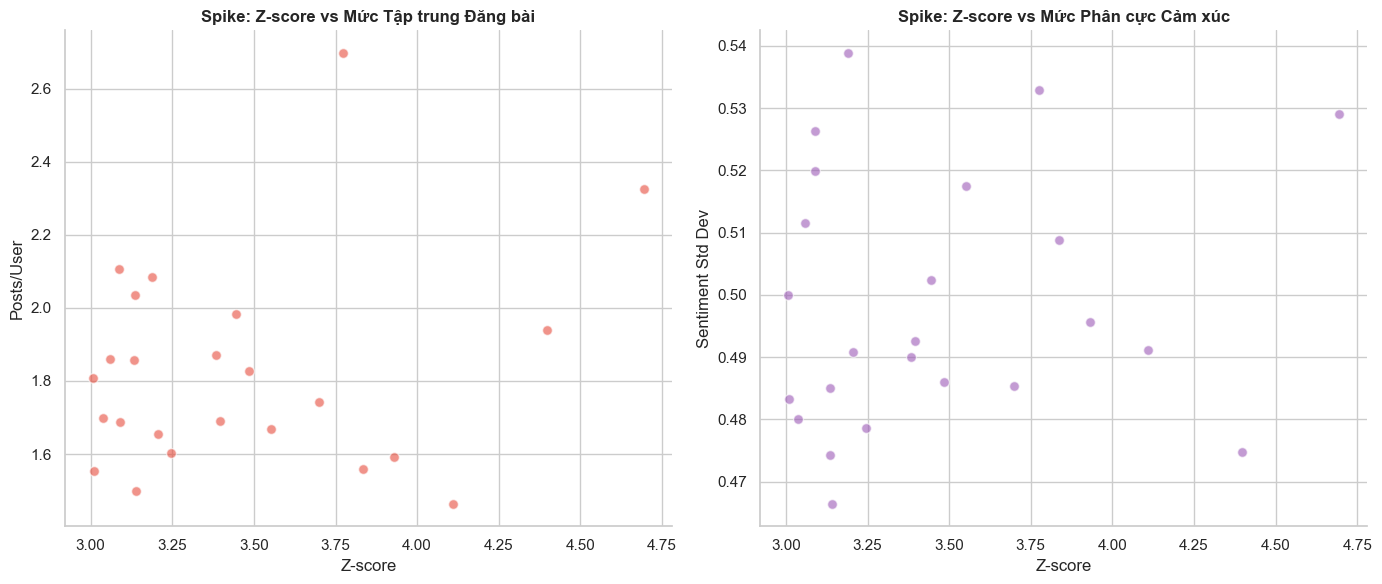

11935

In [117]:
# 8.3 — Đặc điểm Spike: Z-score vs Posts/User & Sentiment Std
spike_days = daily_agg[daily_agg['z_score'] > 3].copy()

if len(spike_days) >= 5:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # Z vs Posts/User
    ax1.scatter(spike_days['z_score'], spike_days['posts_per_user'],
                color='#e74c3c', alpha=0.6, s=50, edgecolors='white')
    ax1.set_xlabel('Z-score')
    ax1.set_ylabel('Posts/User')
    ax1.set_title('Spike: Z-score vs Mức Tập trung Đăng bài')

    # Z vs Sentiment Std
    ax2.scatter(spike_days['z_score'], spike_days['std_sentiment'],
                color='#9b59b6', alpha=0.6, s=50, edgecolors='white')
    ax2.set_xlabel('Z-score')
    ax2.set_ylabel('Sentiment Std Dev')
    ax2.set_title('Spike: Z-score vs Mức Phân cực Cảm xúc')

    for ax in (ax1, ax2):
        sns.despine(ax=ax)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, '16_spike_characteristics.pdf'),
                format='pdf', bbox_inches='tight')
    plt.show()
else:
    print(f"Chỉ có {len(spike_days)} spike days — không đủ để vẽ scatter plot.")

del spike_days
gc.collect()

**Nhận xét — Phát hiện Điểm Bùng phát Bất thường (Kết quả thực tế):**

- **Tần suất xuất hiện (Biểu đồ 15):** Với cửa sổ trượt 28 ngày, phát hiện **24 ngày bùng phát mạnh có $Z\text{-score} > 3$** (chiếm 0.94% trên tổng số 2,557 ngày) và **3 ngày có $Z\text{-score} > 4$**. Đường `Rolling Mean (28d)` phản ánh lưu lượng nền dao động quanh 3,500–6,500 bài/ngày, và 24 điểm spike phân bố rải rác đều khắp 7 năm.
- **Các sự kiện bùng phát tiêu biểu (Bảng Top 15 Spikes & Biểu đồ 15):**
  - **2017-10-26** ($Z = 4.70$, Volume = 14,978 bài, 6,444 users): Đạt Z-score cao nhất tập dữ liệu, đi kèm điểm cảm xúc trung bình chuyển âm (**-0.09**), độ phân cực cao (**Std = 0.53**) và hệ số khuếch đại vọt lên **34.49 COMMENT/POST** (gấp 2.7 lần trung bình).
  - **2016-09-08** ($Z = 4.40$, Volume = 17,054 bài — cao nhất toàn tập, 8,794 users): Thu hút lượng người dùng kỷ lục trong một ngày với hệ số khuếch đại **32.05**.
  - **2020-01-20** ($Z = 4.11$, Volume = 10,879 bài, 7,431 users): Hệ số khuếch đại vọt lên mức cao nhất trong nhóm spike (**60.12 COMMENT/POST**) kèm cảm xúc âm (**-0.02**).
- **Đặc trưng hành vi tại điểm bùng phát (Biểu đồ 16):**
  - *Z-score vs Mức tập trung đăng bài (Biểu đồ 16 trái):* 22/24 ngày spike có tỷ lệ `Posts/User` nằm trong dải bình thường (**1.46 – 2.11 bài/user**), chỉ có 2 ngày tranh luận đặc biệt sôi nổi năm 2017 là `2017-08-08` (2.70 bài/user) và `2017-10-26` (2.32 bài/user). Điều này khẳng định các đợt bùng phát là do hiệu ứng đám đông tự nhiên (viral events) chứ không phải bot spam.
  - *Z-score vs Mức phân cực cảm xúc (Biểu đồ 16 phải):* Hầu hết các ngày spike đi kèm với độ lệch chuẩn cảm xúc cao (`Sentiment Std` phân bố chủ yếu từ **0.485 đến 0.540**) và hệ số khuếch đại lớn (20 – 60 COMMENT/POST).
- **Đề xuất thiết kế cho Pipeline & Gợi ý Thu hẹp Phạm vi (Scoping):**
  1. *Về phạm vi thời gian:* Giai đoạn **2018–2020** (hoặc **2017–2020**) có độ sâu thảo luận cao nhất (`Amplification` tăng từ 12 lên 17), độ phân cực quan điểm rõ nét nhất (`Sentiment Std` ~0.49–0.50) và không bị lỗi khuyết `POST` như đầu năm 2014 — rất lý tưởng để đề xuất nhóm chọn làm khung thời gian trọng tâm khi huấn luyện mô hình khám phá Narrative.
  2. *Về Feature Engineering:* Kết hợp **(1) Z-score Volume / Growth Momentum**, **(2) Amplification Ratio (COMMENT/POST)** và **(3) Sentiment Mean & Polarization (Std)** trong cửa sổ $W_{hist}=7$ ngày làm bộ đặc trưng thời gian cốt lõi.

In [118]:
# Cleanup & Memory Release
daily_agg_clean = daily_agg.drop(columns=['rolling_mean', 'rolling_std', 'z_score'],
                                  errors='ignore')

# Giải phóng bộ nhớ toàn bộ DataFrames
try:
    del df
except NameError:
    pass

del daily_agg_clean
gc.collect()


35